# Xenium: transferred atlas labels and the transplant-rejection cohort

## Motivation

Visium HD resolves the tissue at 2 µm, but a bin is not a cell. Xenium measures a few hundred genes in segmented
single cells, which makes it the right tool to count cells: how many immune cells sit in a biopsy, of which kind,
and whether they lie scattered or packed into foci. A panel of a few hundred genes, however, is too small to
cluster cells into the cell types of the heart atlas from scratch. We therefore transfer the atlas labels to the
Xenium cells with CellPin, which embeds atlas nuclei and Xenium cells into one latent space.

In this notebook we start from two Xenium data sets with their transferred labels: a section of a healthy heart
and a cohort of endomyocardial biopsies taken after heart transplantation. We compare the labels with marker
genes (ED6 i), split the lymphoid cells into Level-4 subtypes, look at the immune cells on the slide (Fig 6 c,
ED6 j), and then analyse the rejection cohort per biopsy core: composition and immune foci (Fig 6 d–e, ED9 a),
cytokine-response programmes by rejection type (Fig 6 h–i, ED9 b–c), the change after treatment (Fig 6 f–g) and
the targets of immunosuppressive drugs (Fig 6 k–l).

## Dataset

| object | content | fields used here |
|---|---|---|
| healthy section `AnnData` (`results/xenium/healthy/xenium_genes.h5ad`) | 10x Genomics "Human Non-diseased Heart (FFPE)", cells × 377 genes, raw counts | `X`, `obsm["spatial"]` (µm) |
| rejection cohort (`results/xenium/inputs/gse290577_aug2025/extracted`) | GEO GSE290577, endomyocardial biopsies on two tissue microarrays, cells × 477 genes, raw counts | `X`, `obsm["spatial"]`, `obs["Sample"]` (biopsy core), `obs["biopsy_rejection_type"]`, `obs["biopsy_cellular_grading"]`, `obs["slide"]` |
| clinical metadata (`GSE290577_heart_spatial_metadata.txt.gz`) | one row per core | patient, day of the biopsy, timing relative to treatment, rejection type, ISHLT grades, outcome |
| atlas reference (`results/xenium/<cohort>/reference_subset.h5ad`) | atlas nuclei, at most 2,000 per Level-3 type | `obs["cell_type"]` |
| transferred labels (`results/xenium/<cohort>/xenium_cellpin_labels.csv`) | one row per cell | Level-3 label and its confidence, lymphoid Level-4 label, immune flag |
| CellPin latent space (`annotation/latent.npz`, `lymphoid_l4/extra_latent.npz`) | position of the Xenium cells and of the atlas T and NK cells | input of the Level-4 transfer |
| cytokine programmes (`resources/atlas/cytokine_programs.json`) | huCIRA response genes per cytokine and immune cell type | gene sets |

A biopsy core is the unit of the tissue microarray (`Sample`); a *biopsy* is a patient on one day and has one or
two cores. The analysis steps live in `hhca.tl` and the figure panels in `hhca.pl`; the scripts in
`scripts/xenium/downstream/` and `figures/` call the same functions.

## Environment setup

We load the packages, set the scanpy defaults and keep the log of the neighbourhood graph quiet;
`style.notebook()` gives the plots of this notebook the font and open axes of the figure panels. All paths in the configuration are relative to the repository root, so we work
from there.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import json
import logging
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import squidpy as sq
from scipy import stats

import hhca
from hhca.config import load_config
from hhca.pl import style

sc.settings.verbosity = 0
logging.getLogger("spatialdata._logging").setLevel(logging.WARNING)
sc.settings.set_figure_params(dpi=80, facecolor="white", frameon=False)
style.notebook()
np.random.seed(0)
os.chdir(hhca.REPO)

The parameters of the label transfer are set in `config/xenium.yaml`, those of the analyses in
`config/xenium_downstream.yaml`. We read both and look at the thresholds; gene lists and cell classes are shown
where they are used.

In [2]:
transfer = load_config("xenium")
cfg = load_config("xenium_downstream")
labels = cfg["labels"]
classes = cfg["classes"]
params = cfg["params"]
pd.Series(
    {
        "neighbours of the label transfer": transfer["annotate"]["k"],
        "held-out F1 a class needs": transfer["annotate"]["min_f1_reliable"],
        "focus radius (µm)": params["dbscan"]["eps_um"],
        "cells in a dense neighbourhood": params["dbscan"]["min_samples"],
        "control genes of a gene-set score": params["cytokine"]["ctrl_size"],
        "cells per core and cell type": params["celltype_cytokine"]["min_cells"],
        "immune cells of a core in the overview": params["fig6d_min_immune"],
        "permutations": params["permutations"],
    },
    name="value",
    dtype=object,
).to_frame()

,value
neighbours of the label transfer,25
held-out F1 a class needs,0.5
focus radius (µm),30.0
cells in a dense neighbourhood,5
control genes of a gene-set score,50
cells per core and cell type,10
immune cells of a core in the overview,25
permutations,5000


## Loading data

The healthy section is one `AnnData` of cells × genes with raw counts and the cell centroids in
`obsm["spatial"]`.

In [3]:
healthy = sc.read_h5ad("results/xenium/healthy/xenium_genes.h5ad")
healthy

AnnData object with n_obs × n_vars = 26366 × 377
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'cell_area', 'nucleus_area', 'total_counts', 'n_genes'
    var: 'gene_ids', 'feature_types', 'genome'
    obsm: 'spatial'
    layers: 'counts'

The rejection cohort was published as a Seurat object; `scripts/xenium/extract_mtx.R` writes its counts, metadata
and cell geometry, and `hhca.io.read_xenium_cohort` reads them as an `AnnData` of the same layout.

In [4]:
adata = hhca.io.read_xenium_cohort(cfg["inputs"]["extracted"])
adata

AnnData object with n_obs × n_vars = 162638 × 477
    obs: 'cell_id', 'Sample', 'patient_id', 'patient_biopsy', 'ct_second_pass', 'lineage', 'biopsy_rejection_type', 'patient_rejection_type', 'biopsy_cellular_grading', 'biopsy_antibody_grading', 'biopsy_timing', 'slide', 'age_at_biopsy', 'sex', 'total_counts', 'nCount_Xenium', 'nFeature_Xenium', 'barcode'
    obsm: 'spatial'

Every cell carries the core it belongs to (`Sample`) and the clinical annotation of that core.

In [5]:
adata.obs[["Sample", "patient_id", "biopsy_timing", "biopsy_rejection_type", "biopsy_cellular_grading", "slide"]].head()

,Sample,patient_id,biopsy_timing,biopsy_rejection_type,biopsy_cellular_grading,slide
aaadcmfp-1_1,Patient_14_2,Patient_14,pre,no_rejection,1.0,slide1
aaaghlda-1_1,Patient_14_2,Patient_14,pre,no_rejection,1.0,slide1
aaagknni-1_1,Patient_14_2,Patient_14,pre,no_rejection,1.0,slide1
aaagpcee-1_1,Patient_14_2,Patient_14,pre,no_rejection,1.0,slide1
aaahgnnl-1_1,Patient_14_2,Patient_14,pre,no_rejection,1.0,slide1


In [6]:
cores_of_cohort = adata.obs.drop_duplicates("Sample")
rejection_type = cores_of_cohort["biopsy_rejection_type"].fillna("not recorded")
pd.crosstab(rejection_type, cores_of_cohort["biopsy_timing"], margins=True)

biopsy_timing,post,pre,All
biopsy_rejection_type,,,
antibody_rejection,8,17,25
cellular_rejection,21,33,54
mixed_rejection,0,10,10
no_rejection,76,21,97
not recorded,4,5,9
All,109,86,195


The clinical table of the cohort has one row per core. `hhca.tl.clinical_metadata` adds the columns we use
later: the rejection type of the core (`rej`), the ISHLT cellular grade of the biopsy (`grade`), the antibody
grade (`pamr`) and the biopsy the core belongs to (`bxid`, patient and day after transplantation).

In [7]:
clinical_table = pd.read_csv(cfg["inputs"]["metadata"], sep="\t")
metadata = hhca.tl.clinical_metadata(clinical_table)
n_biopsies = metadata["bxid"].nunique()
n_patients = metadata["patient_id"].nunique()
print(f"{len(metadata)} cores, {n_biopsies} biopsies, {n_patients} patients")
metadata[["Sample", "bxid", "biopsy_timing", "rej", "grade", "pamr", "resolution_broad"]].head()

195 cores, 108 biopsies, 62 patients


,Sample,bxid,biopsy_timing,rej,grade,pamr,resolution_broad
0,Patient_14_2,Patient_14@d971,pre,no_rejection,3,pAMR1-h,NaN
1,Patient_46_2,Patient_46@d761,pre,mixed_rejection,2,pAMR1-i,resolved
2,Patient_3_2,Patient_3@d86,pre,cellular_rejection,3,pAMR0,resolved
3,Patient_14_1,Patient_14@d971,pre,cellular_rejection,3,pAMR1-h,NaN
4,Patient_3_3,Patient_3@d92,post,no_rejection,1,pAMR0,resolved


The cohort has 195 cores from 108 biopsies of 62 patients. 97 cores show no rejection, 54 cellular, 25
antibody-mediated and 10 mixed rejection; 86 cores were taken before and 109 after treatment.

### Transferred labels

The reference of the label transfer is a subsample of the heart atlas with at most 2,000 nuclei per Level-3 type
(`sbatch workflow/hpc/xenium_reference.sbatch <cohort>`).

In [8]:
reference = sc.read_h5ad("results/xenium/rejection/reference_subset.h5ad", backed="r")
reference

AnnData object with n_obs × n_vars = 40148 × 3257 backed at 'results/xenium/rejection/reference_subset.h5ad'
    obs: 'cell_type', 'donor_id', 'cell_type_L4', 'atlas_row'
    var: 'gene_id_orig'
    layers: 'counts'

CellPin is trained on this reference and embeds the Xenium cells into its latent space, where every cell takes
the Level-3 label of its 25 nearest atlas nuclei, weighted by distance
(`sbatch workflow/hpc/xenium_cellpin.sbatch <cohort>`). Training and transfer take about an hour, so we load
their result. One fifth of the reference was held out to measure how well each label is recovered:

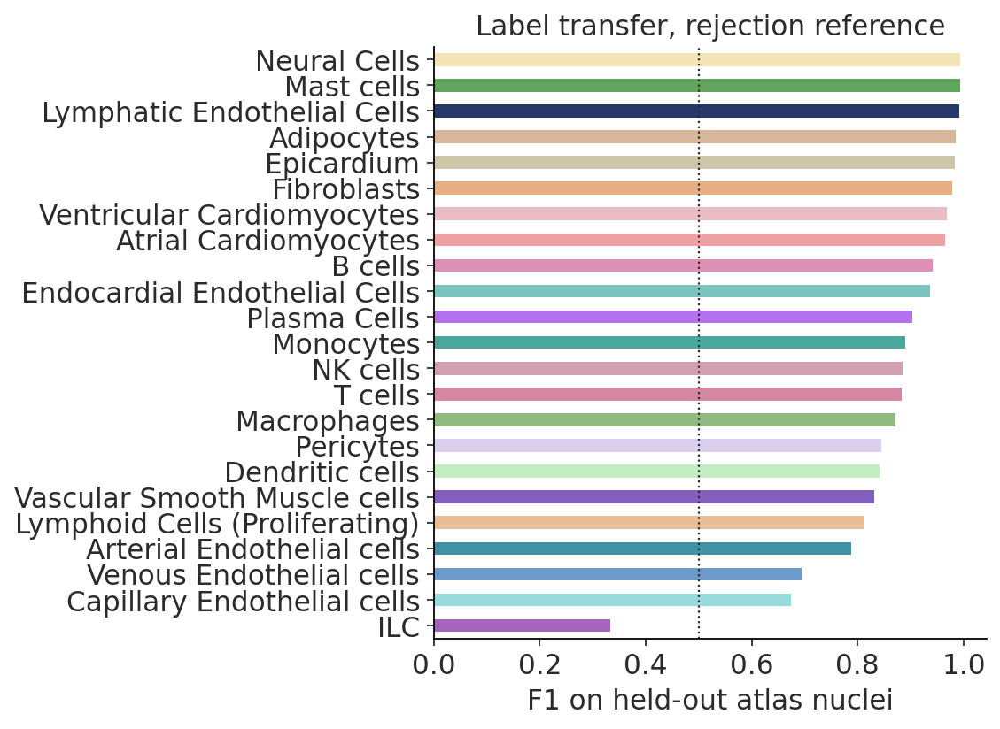

,healthy,rejection
class,,
ILC,0.35,0.33
Capillary Endothelial cells,0.63,0.67
Venous Endothelial cells,0.60,0.69


In [9]:
f1_by_cohort = {}
for cohort in ("healthy", "rejection"):
    per_class = pd.read_csv(f"results/xenium/{cohort}/annotation/heldout_L3_perclass.csv", index_col="class")
    f1_by_cohort[cohort] = per_class["f1"]
f1 = pd.DataFrame(f1_by_cohort).sort_values("rejection")

colours = [style.CT[name] for name in f1.index]
ax = f1["rejection"].plot.barh(color=colours, figsize=(5, 5.5))
ax.axvline(transfer["annotate"]["min_f1_reliable"], color=style.INK, lw=1, ls=":")
ax.set(xlabel="F1 on held-out atlas nuclei", ylabel="", title="Label transfer, rejection reference")
plt.show()
f1.head(3).round(2)

We add the transferred labels to the cells. For the healthy section these are the Level-3 label and its
confidence. For the rejection cohort `hhca.tl.atlas_labels` adds `atlas_L3` (the Level-3 label, with atrial and
ventricular cardiomyocytes joined, because the panel has no chamber markers), `atlas_immune` and the lymphoid
Level-4 label `label8`, which we come back to below.

In [10]:
healthy_labels = pd.read_csv("results/xenium/healthy/xenium_cellpin_labels.csv", index_col="cell_id")
healthy.obs["cellpin_L3"] = healthy_labels["cellpin_L3"]
healthy.obs["cellpin_L3_conf"] = healthy_labels["cellpin_L3_conf"]

cellpin = pd.read_csv("results/xenium/rejection/xenium_cellpin_labels.csv")
hhca.tl.atlas_labels(
    adata, cellpin, pool=labels["pool_cardiomyocytes"], exclude=labels["exclude_l3"], lymphoid=labels["lymphoid"]
)
adata.obs[["Sample", "atlas_L3", "atlas_immune", "label8", "label8_confidence"]].head()

,Sample,atlas_L3,atlas_immune,label8,label8_confidence
aaadcmfp-1_1,Patient_14_2,Venous Endothelial cells,False,NaN,NaN
aaaghlda-1_1,Patient_14_2,T cells,True,CD8 T cells,0.8143
aaagknni-1_1,Patient_14_2,T cells,True,CD8 T cells,0.9082
aaagpcee-1_1,Patient_14_2,NK cells,True,CD8 T cells,0.5959
aaahgnnl-1_1,Patient_14_2,NK cells,True,CD8 T cells,0.8407


How many cells of the cohort carry an immune label, and how many are labelled ILC?

In [11]:
n_immune = adata.obs["atlas_immune"].sum()
n_ilc = (adata.obs["atlas_L3"] == "ILC").sum()
print(f"{adata.n_obs:,} cells, {n_immune:,} immune, {n_ilc} ILC")

162,638 cells, 72,487 immune, 10 ILC


Of the 162,638 cells of the cohort, 72,487 carry an immune label. ILC is the only class with a held-out F1
below 0.5 (0.33); its 10 cells are not counted as immune cells.

## Quality control

Before we use the labels we look at the cells themselves. `sc.pp.calculate_qc_metrics` gives the number of
transcripts and of detected genes per cell.

In [12]:
healthy_qc, _ = sc.pp.calculate_qc_metrics(healthy, percent_top=None, log1p=False)
cohort_qc, _ = sc.pp.calculate_qc_metrics(adata, percent_top=None, log1p=False)
qc = pd.concat({"healthy section": healthy_qc, "rejection cohort": cohort_qc}, names=["dataset"])
qc = qc.reset_index("dataset")
qc.groupby("dataset")[["total_counts", "n_genes_by_counts"]].median()

,total_counts,n_genes_by_counts
dataset,,
healthy section,63.0,24.0
rejection cohort,53.0,34.0


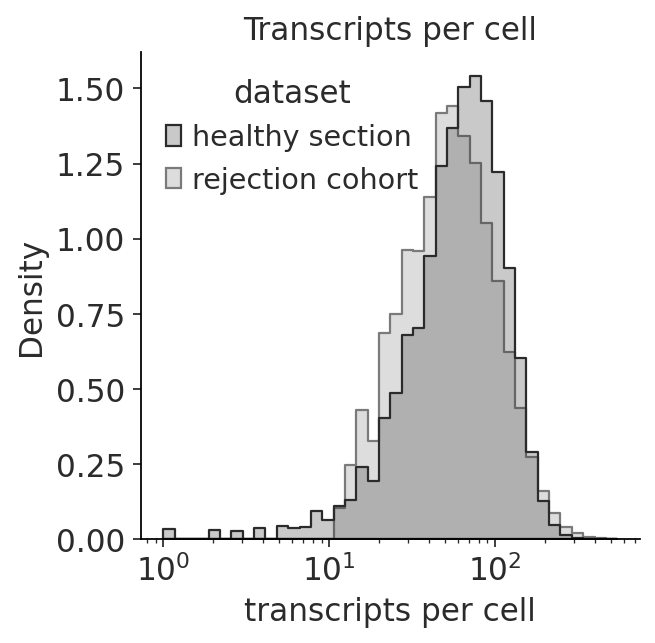

In [13]:
ax = sns.histplot(
    qc,
    x="total_counts",
    hue="dataset",
    palette=style.XENIUM_DATASET,
    log_scale=True,
    bins=40,
    element="step",
    stat="density",
    common_norm=False,
)
ax.set(xlabel="transcripts per cell", title="Transcripts per cell")
plt.show()

The cores of the rejection cohort differ in size, which is why all later quantities are fractions or means per
core.

In [14]:
cells_per_core = adata.obs["Sample"].value_counts()
cells_per_core.describe().loc[["count", "min", "50%", "max"]].to_frame("cells per core")

,cells per core
count,195.0
min,45.0
50%,760.0
max,2485.0


A cell holds a median of 63 transcripts of 24 genes on the healthy section and 53 transcripts of 34 genes in the
rejection cohort, and a core between 45 and 2,485 cells (median 760).

For the expression-based steps we keep the raw counts in a layer and normalise to counts per 10,000 followed by
`log1p`. The healthy section is normalised after the next step, which needs its raw counts.

In [15]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata

AnnData object with n_obs × n_vars = 162638 × 477
    obs: 'cell_id', 'Sample', 'patient_id', 'patient_biopsy', 'ct_second_pass', 'lineage', 'biopsy_rejection_type', 'patient_rejection_type', 'biopsy_cellular_grading', 'biopsy_antibody_grading', 'biopsy_timing', 'slide', 'age_at_biopsy', 'sex', 'total_counts', 'nCount_Xenium', 'nFeature_Xenium', 'barcode', 'atlas_L3', 'atlas_immune', 'lymphoid_lineage', 'label8', 'label8_confidence'
    uns: 'log1p'
    obsm: 'spatial'
    layers: 'counts'

## Labels on the healthy section

On the healthy section we can judge the labels by eye, because the anatomy is known. Two adjustments make the
map honest about what a 377-gene panel can tell. Cardiomyocytes are shown as one class. And endothelial cells are
a special case: cardiomyocytes are large, and a segment of capillary next to them is easily merged into a
neighbouring cell. `hhca.tl.endothelial_gate` therefore shows an endothelial subtype only for cells that express
endothelial genes: the transcripts of the pan-endothelial markers (plus the lymphatic markers for lymphatic
endothelium) must be at least two and at least 5% of all transcripts of the cell. The function adds the display
class as `healthy.obs["display"]`.

In [16]:
ed6i = cfg["ed6i"]
hhca.tl.endothelial_gate(
    healthy,
    healthy.obs["cellpin_L3"],
    ed6i["ec_classes"],
    ed6i["ec_markers"],
    ed6i["lymphatic_markers"],
    min_counts=ed6i["ec_min_counts"],
    min_fraction=ed6i["ec_min_fraction"],
    pool=ed6i["pool_cardiomyocytes"],
    negative_label=ed6i["ec_negative_label"],
)
endothelial = healthy.obs[healthy.obs["cellpin_L3"].isin(ed6i["ec_classes"])]
pd.crosstab(endothelial["cellpin_L3"], endothelial["ec_gate_pass"], margins=True)

ec_gate_pass,False,True,All
cellpin_L3,,,
Arterial Endothelial cells,733,1390,2123
Capillary Endothelial cells,8,43,51
Endocardial Endothelial Cells,28,113,141
Lymphatic Endothelial Cells,5,93,98
Venous Endothelial cells,25,332,357
All,799,1971,2770


The number of cells per display class:

In [17]:
healthy.obs["display"].value_counts().to_frame("cells")

,cells
display,
Cardiomyocytes,20121
Arterial EC,1390
Fibroblasts,1267
Smooth muscle,802
"EC label, marker-negative",799
Epicardium,365
Venous EC,332
Neural,196
Dendritic cells,184


We plot the cells at their centroids in the colours of the panels (`style.XENIUM`); cells with an endothelial
label that fail the gate are grey.

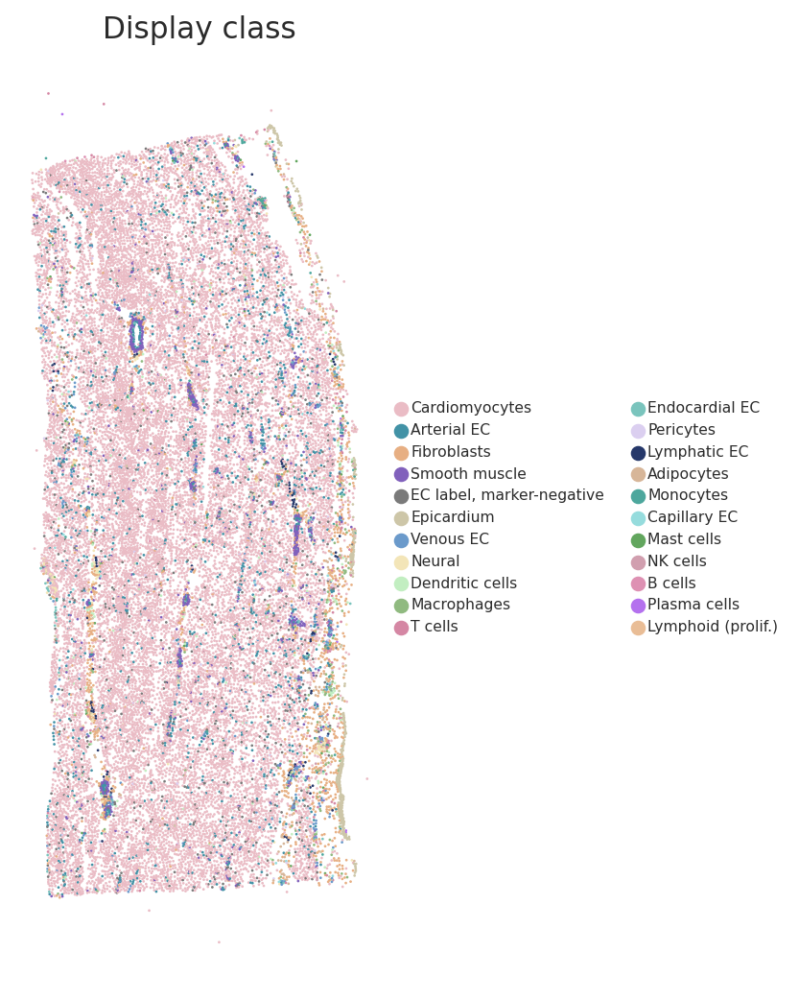

In [18]:
largest_first = healthy.obs["display"].value_counts().index
healthy.obs["display"] = pd.Categorical(healthy.obs["display"], categories=largest_first)
style.set_colors(healthy, "display", style.XENIUM, default=style.MUTED)
with plt.rc_context({"figure.figsize": (4.5, 8)}):
    ax = sc.pl.embedding(
        healthy, basis="spatial", color="display", size=6, legend_fontsize=7, title="Display class", show=False
    )
ax.invert_yaxis()
ax.set_aspect("equal")
plt.show()

Do the classes express the genes we expect of them? We normalise the counts and plot marker genes of the panel
per display class, each gene scaled between its lowest and highest class.

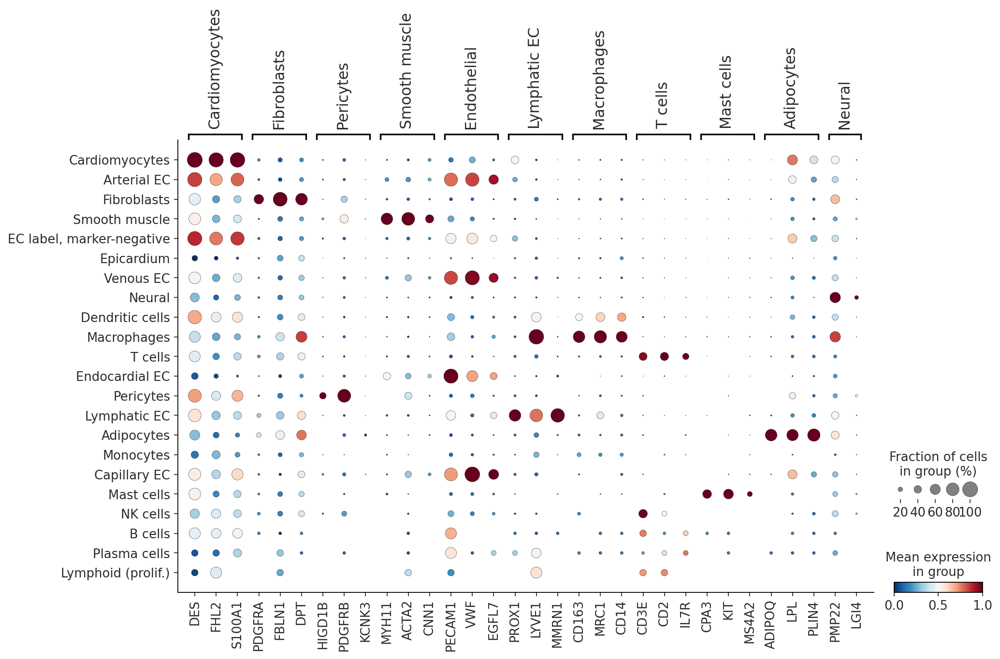

In [19]:
sc.pp.normalize_total(healthy, target_sum=1e4)
sc.pp.log1p(healthy)
sc.pl.dotplot(healthy, cfg["markers"]["healthy"], groupby="display", standard_scale="var", cmap=style.DIVERGING)

`hhca.pl.healthy_section` draws ED6 i: the section with one vascular field enlarged.

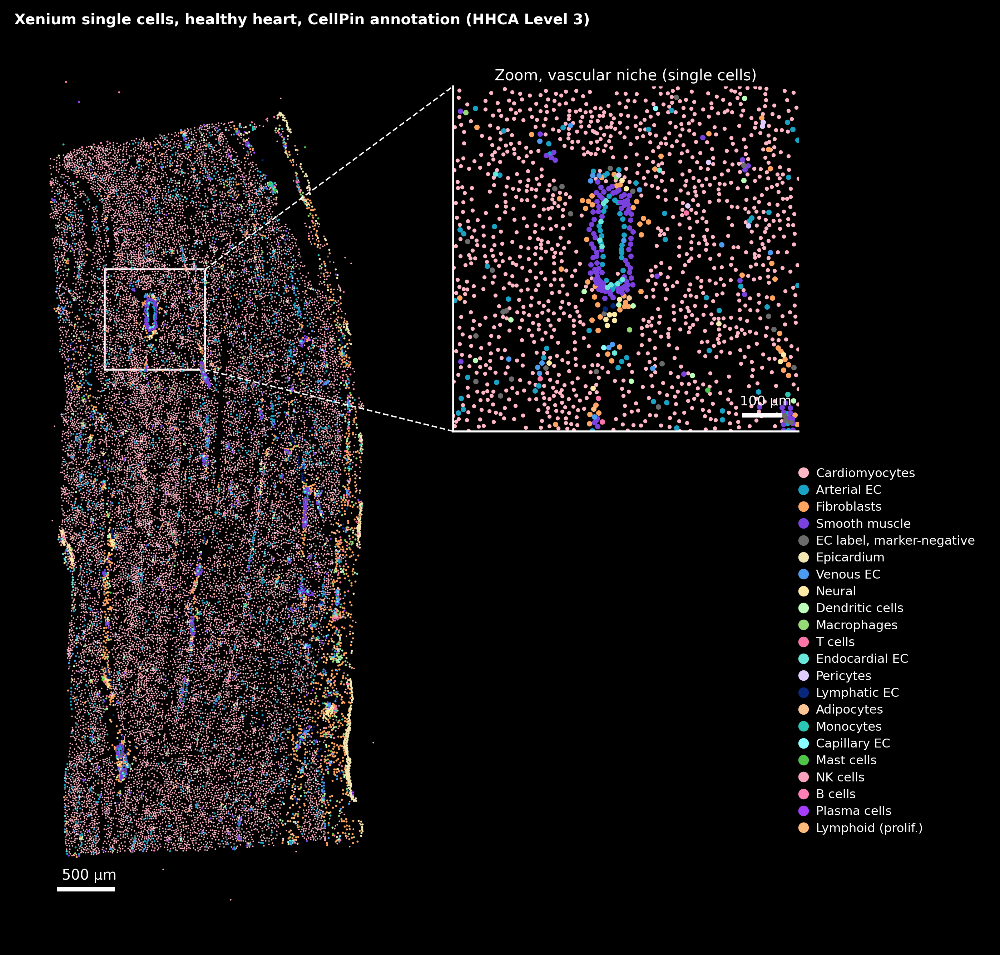

In [20]:
healthy_cells = healthy.obs.rename(columns={"x_centroid": "x", "y_centroid": "y"})
fig = hhca.pl.healthy_section(healthy_cells, ed6i["ec_negative_label"])

Of the 26,366 cells of the section, 20,121 are cardiomyocytes. 1,971 of the 2,770 cells with an endothelial label
pass the gate; 733 of the 799 that fail are labelled arterial endothelium, and in the dot plot this class
expresses cardiomyocyte genes more than endothelial ones. The other classes express the markers of their type.

## Labels in the rejection cohort

The biopsies are small and inflamed, so here the immune cells matter most. First the number of cells per Level-3
label:

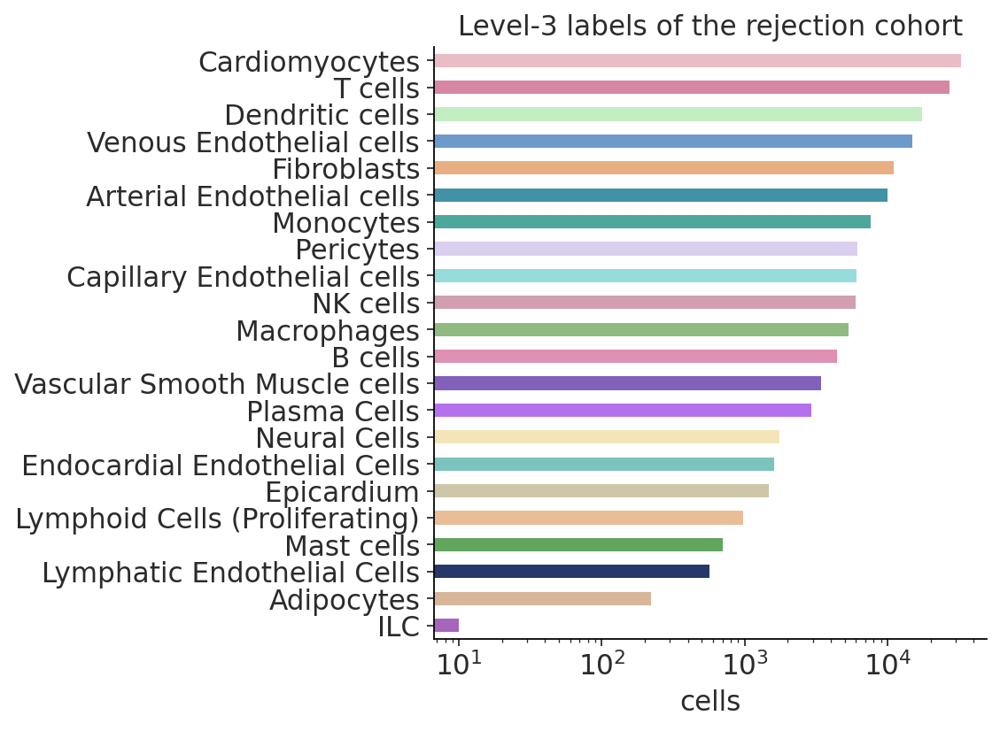

In [21]:
cells_per_label = adata.obs["atlas_L3"].value_counts().sort_values()
colours = [style.XENIUM[name] for name in cells_per_label.index]
ax = cells_per_label.plot.barh(color=colours, figsize=(5, 5.5))
ax.set(xscale="log", xlabel="cells", ylabel="", title="Level-3 labels of the rejection cohort")
plt.show()

And their marker genes on the 477-gene panel, again scaled per gene:

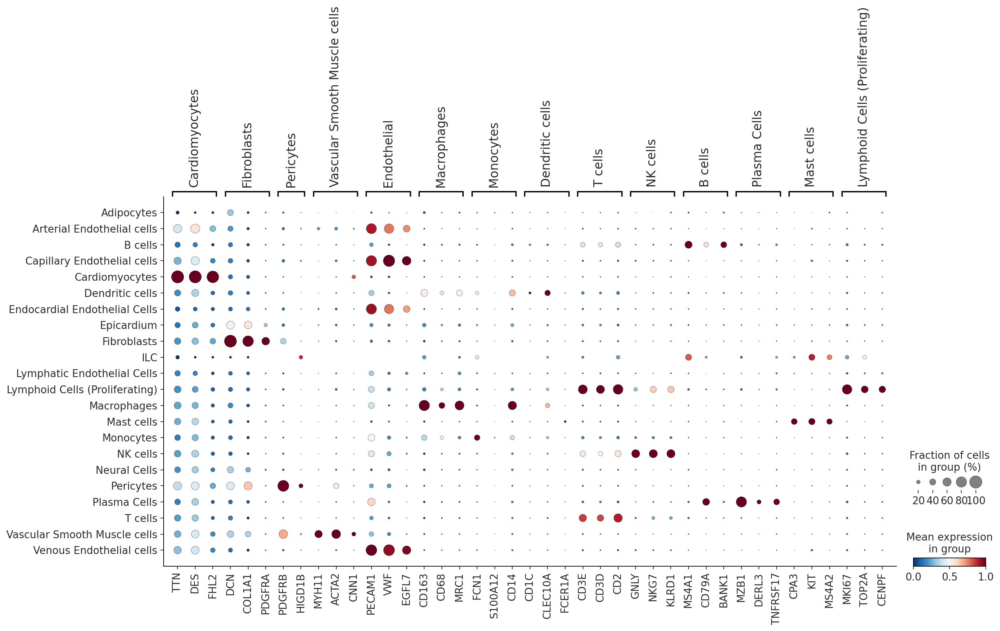

In [22]:
sc.pl.dotplot(adata, cfg["markers"]["rejection"], groupby="atlas_L3", standard_scale="var", cmap=style.DIVERGING)

The 72,487 immune cells and the structural classes express the markers of their type; the 10 cells labelled ILC
show no profile of their own, in line with their exclusion.

## Lymphoid subtypes (Level 4)

Rejection is driven by T cells, and "T cells" is too coarse a label for it. The lymphoid compartment (cells
labelled T cells, NK cells or proliferating lymphoid cells) is therefore split further. The lineage (CD4 T,
CD8 T, regulatory T or NK) is transferred in the same CellPin latent space, but from *all* atlas T and NK cells
rather than the subsample, and proliferation is taken from the Level-3 label.

The pipeline (`scripts/xenium/lymphoid_level4.py`) embeds the atlas cells with the trained model and saves their
latent positions. We load them together with the Level-4 annotation of these atlas cells and group the Level-4
states into lineages.

In [23]:
level4_cfg = transfer["lymphoid_l4"]
latent = np.load("results/xenium/rejection/annotation/latent.npz", allow_pickle=True)
atlas_lymphoid = sc.read_h5ad("results/xenium/rejection/reference_extra_lymphoid.h5ad", backed="r")
atlas_latent = np.load("results/xenium/rejection/lymphoid_l4/extra_latent.npz", allow_pickle=True)["emb"]

lineage_of = {}
for lineage_name, states in level4_cfg["lineage_from_L4"].items():
    for state in states:
        lineage_of[state] = lineage_name
lineage = atlas_lymphoid.obs["cell_type_L4"].astype(str).map(lineage_of)
lineage.value_counts(dropna=False).to_frame("atlas cells")

,atlas cells
cell_type_L4,
CD8 T,6426
CD4 T,5290
NK,2896
NaN,1682
Treg,262


Atlas cells without a lineage (γδ and MAIT T cells, ILC, proliferating cells) are not used. `hhca.tl.lymphoid_level4`
standardised latent positions in, labels out: it takes the 25 nearest atlas cells of every Xenium cell of the
compartment, votes on the lineage with distance weights and prefixes the label of proliferating cells.

In [24]:
latent_mean = latent["mu"]
latent_sd = latent["sd"]
xenium_latent = (latent["xen_emb"] - latent_mean) / latent_sd
atlas_latent_scaled = (atlas_latent - latent_mean) / latent_sd
with_lineage = lineage.notna().to_numpy()
cellpin_level3 = pd.Series(cellpin["cellpin_L3"].to_numpy(), index=adata.obs_names)

level4 = hhca.tl.lymphoid_level4(
    xenium_latent,
    cellpin_level3,
    reference_latent=atlas_latent_scaled[with_lineage],
    reference_lineage=lineage[with_lineage].to_numpy(),
    compartment=level4_cfg["compartment_L3"],
    proliferating=level4_cfg["proliferating_L3"],
    names=level4_cfg["pretty"],
    k=transfer["annotate"]["k"],
)
level4.head()

,L3,lineage,is_prolif,label8,confidence
aaaghlda-1_1,T cells,CD8 T cells,False,CD8 T cells,0.8143
aaagknni-1_1,T cells,CD8 T cells,False,CD8 T cells,0.9082
aaagpcee-1_1,NK cells,CD8 T cells,False,CD8 T cells,0.5959
aaahgnnl-1_1,NK cells,CD8 T cells,False,CD8 T cells,0.8407
aaaiacbf-1_1,NK cells,CD8 T cells,False,CD8 T cells,0.7164


The pipeline writes these labels to the label table, from which `hhca.tl.atlas_labels` added them to the cells as
`label8` above. Per class:

In [25]:
print(f"{len(level4):,} lymphoid cells")
level4["label8"].value_counts().to_frame("cells")

33,965 lymphoid cells


,cells
label8,
CD4 T cells,15944
CD8 T cells,14030
NK cells,3012
Proliferating CD8 T cells,684
Proliferating CD4 T cells,253
Proliferating NK cells,42


No cell is labelled regulatory T cell. The held-out atlas cells show why: the lineage transfer does not recover
this small class, so a Treg label on Xenium would not be trustworthy and the analyses work with six classes.

In [26]:
with open("results/xenium/rejection/lymphoid_l4/lymphoid_l4_summary.json") as handle:
    heldout = json.load(handle)["heldout_full_reference"]
pd.DataFrame(heldout["per_class"]).T.round(2)

,precision,recall,f1,support
CD4 T,0.73,0.81,0.77,1058.0
Treg,0.00,0.00,0.00,53.0
CD8 T,0.75,0.73,0.74,1285.0
NK,0.86,0.84,0.85,579.0


The markers of the panel support the split: lineage genes separate CD4 T, CD8 T and NK cells, and the cell-cycle
genes mark the proliferating classes.

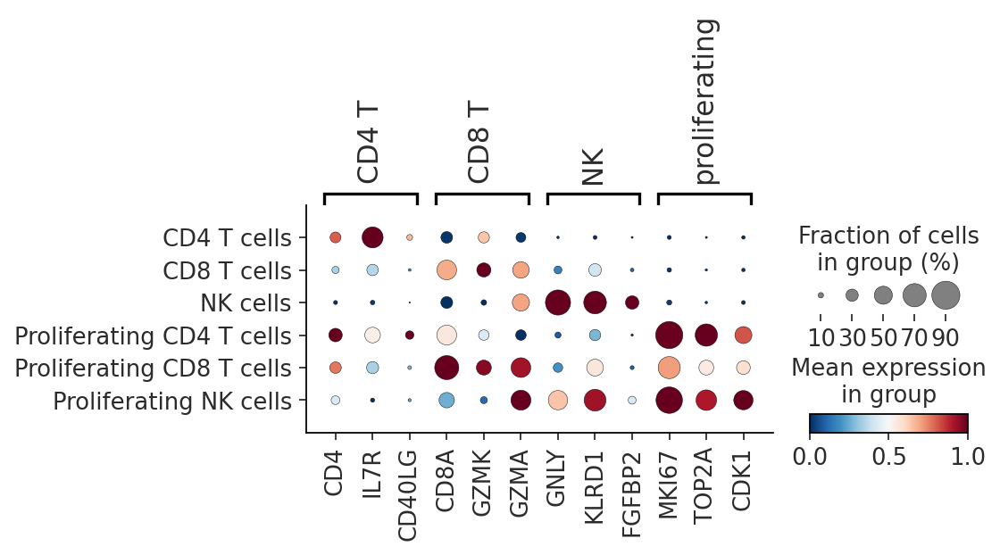

In [27]:
lymphoid = adata[adata.obs["label8"].notna()]
sc.pl.dotplot(lymphoid, cfg["markers"]["lymphoid"], groupby="label8", standard_scale="var", cmap=style.DIVERGING)

The 33,965 lymphoid cells split into 15,944 CD4 T, 14,030 CD8 T and 3,012 NK cells and 684, 253 and 42
proliferating CD8 T, CD4 T and NK cells. On held-out atlas cells the lineage is recovered with an F1 of 0.77
(CD4 T), 0.74 (CD8 T) and 0.85 (NK), and for none of the 53 regulatory T cells.

## Immune cells on the slide

With labels at hand we can look at the tissue. `hhca.tl.spatial_classes` returns one row per cell with its
centroid and the two sets of classes drawn on tissue: the lymphoid Level-4 classes next to six other immune
types (`fig6c`), and coarse immune lineages (`ed6j`).

In [28]:
cells = hhca.tl.spatial_classes(
    adata, classes["slide_immune"], labels["lymphoid"], classes["lineage"], exclude=labels["exclude_l3"]
)
cells["ed6j"].value_counts().to_frame("cells")

,cells
ed6j,
structural / other,90151
T / NK,32986
Monocyte / DC,25134
B / Plasma,7352
Macrophage,5329
Lymphoid (prolif.),979
Mast,707


One core with high-grade cellular rejection, in the colours of the panel:

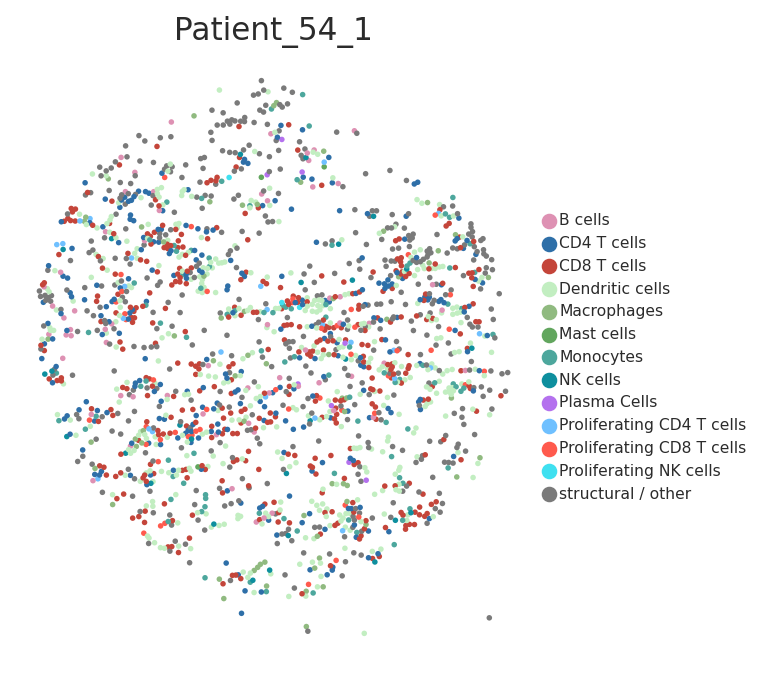

In [29]:
zoom_core = cfg["figures"]["fig6c_zoom_core"]
core = adata[adata.obs["Sample"] == zoom_core].copy()
core.obs["fig6c"] = core.obs["fig6c"].astype(object).fillna("structural / other")
style.set_colors(core, "fig6c", style.IMMUNE_CLASS)
with plt.rc_context({"figure.figsize": (5, 5)}):
    ax = sc.pl.embedding(core, basis="spatial", color="fig6c", size=25, legend_fontsize=7, title=zoom_core, show=False)
ax.invert_yaxis()
ax.set_aspect("equal")
plt.show()

`hhca.pl.slide_immune_cells` draws Fig 6 c, the tissue microarray with the most cores and this core enlarged.

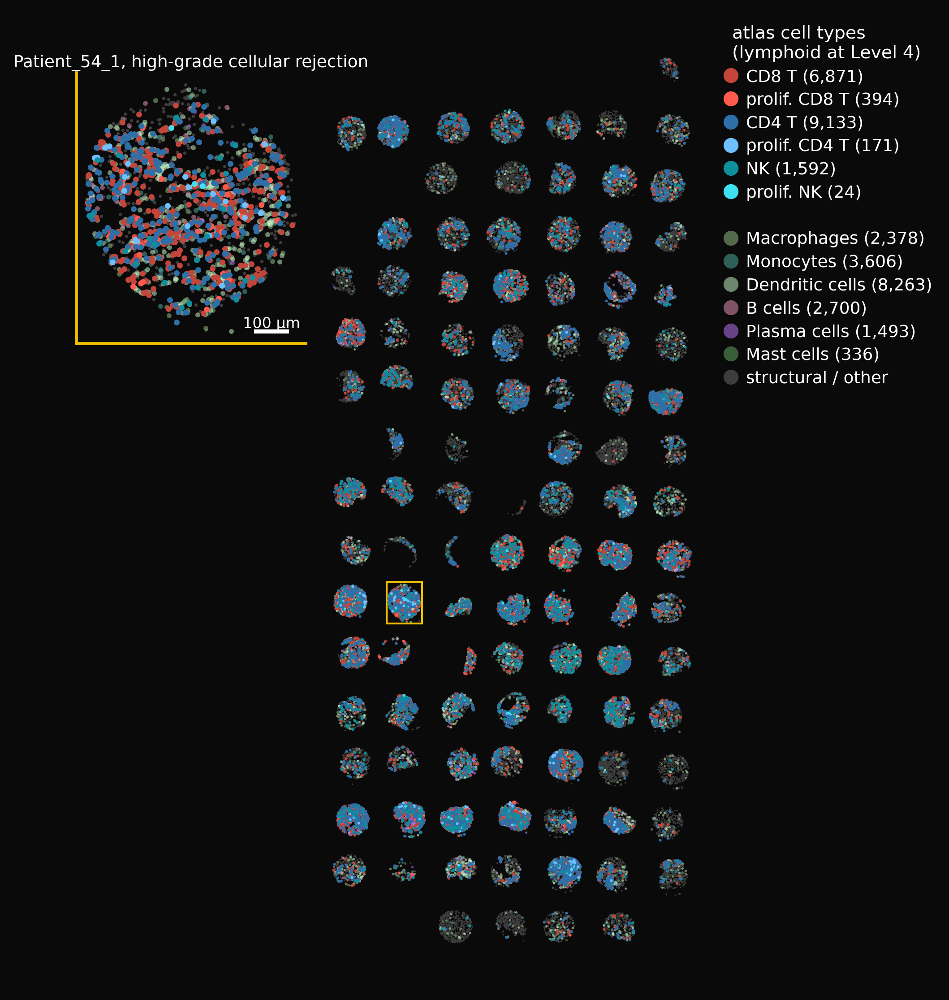

In [30]:
fig = hhca.pl.slide_immune_cells(cells, zoom_core, labels["lymphoid"], classes["slide_immune"])

`hhca.pl.core_lineages` draws ED6 j: a core of grade 1R and a core of grade 3R with their immune lineages.

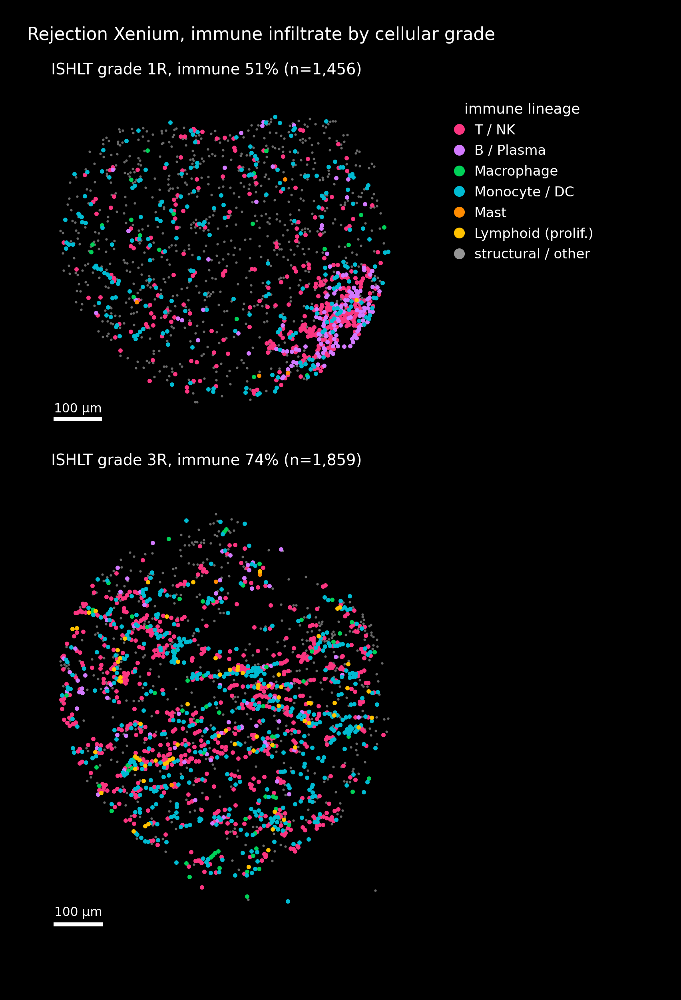

In [31]:
fig = hhca.pl.core_lineages(cells, cfg["figures"]["ed6j_cores"])

Of the cells of the cohort, 90,151 are structural; the immune cells are 32,986 T or NK cells, 25,134 monocytes or
dendritic cells, 7,352 B or plasma cells, 5,329 macrophages, 979 proliferating lymphoid cells and 707 mast cells.

## Immune foci and composition per core

Pathologists grade cellular rejection by how dense and how focal the infiltrate is. We measure both per core.
An immune focus is a group of immune cells that lie close together: `hhca.tl.immune_foci` runs DBSCAN on the
centroids of the immune cells of every core (radius 30 µm, at least five cells in a dense neighbourhood) and
returns the immune fraction, the share of immune cells that lie in a focus and the size of the largest focus.
It also flags the cells in a focus as `adata.obs["in_focus"]`.

In [32]:
dbscan = params["dbscan"]
foci = hhca.tl.immune_foci(adata, "atlas_immune", eps=dbscan["eps_um"], min_samples=dbscan["min_samples"])
foci.head()

,n_total,n_immune,immune_fraction,dbscan_frac_in_agg,dbscan_largest_agg_cells,dbscan_n_aggregates
Sample,,,,,,
Patient_10_1,670,362,0.540299,0.790055,150.0,7
Patient_10_2,780,113,0.144872,0.159292,13.0,2
Patient_10_3,1110,520,0.468468,0.823077,214.0,18
Patient_11_1,970,509,0.524742,0.848723,137.0,19
Patient_11_2,1013,645,0.636723,0.893023,296.0,18


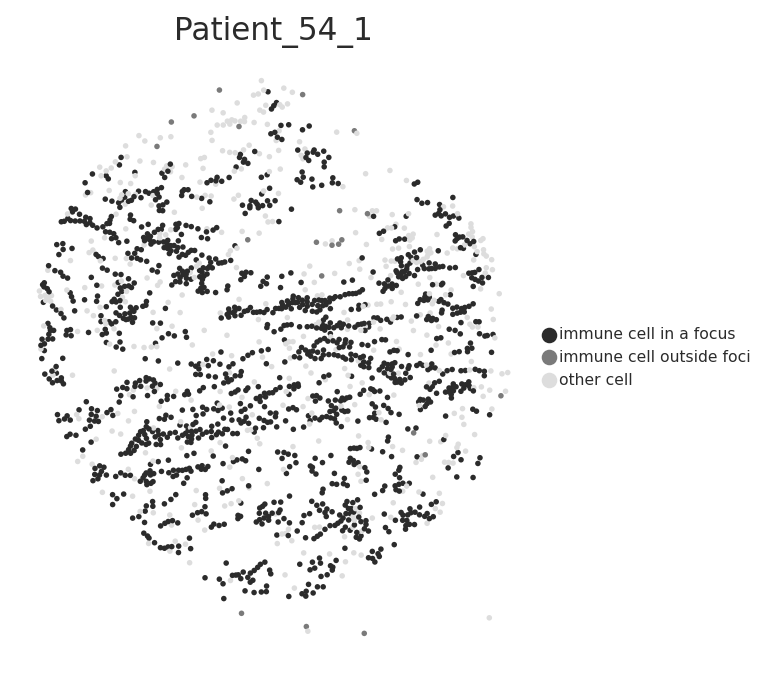

In [33]:
core = adata[adata.obs["Sample"] == zoom_core].copy()
focus = np.select(
    [core.obs["in_focus"], core.obs["atlas_immune"]],
    ["immune cell in a focus", "immune cell outside foci"],
    default="other cell",
)
core.obs["focus"] = pd.Categorical(focus, categories=list(style.FOCUS))
style.set_colors(core, "focus", style.FOCUS)
with plt.rc_context({"figure.figsize": (5, 5)}):
    ax = sc.pl.embedding(core, basis="spatial", color="focus", size=25, legend_fontsize=7, title=zoom_core, show=False)
ax.invert_yaxis()
ax.set_aspect("equal")
plt.show()

What makes a focus can be read off a neighbourhood graph. `sq.gr.spatial_neighbors` connects the immune cells of
the core that lie within 30 µm of each other. A cell with at least four such neighbours has a dense
neighbourhood, and a focus consists of these cells and their neighbours:

In [34]:
immune = core[core.obs["atlas_immune"]].copy()
sq.gr.spatial_neighbors(immune, coord_type="generic", radius=dbscan["eps_um"])
graph = immune.obsp["spatial_connectivities"]
n_neighbours = np.asarray(graph.sum(axis=1)).ravel()
min_neighbours = dbscan["min_samples"] - 1  # DBSCAN counts the cell itself among its min_samples
dense = n_neighbours >= min_neighbours
n_dense = dense.sum()
n_in_focus = immune.obs["in_focus"].sum()
print(f"{zoom_core}: {immune.n_obs:,} immune cells, {n_dense:,} with a dense neighbourhood, {n_in_focus:,} in a focus")

Patient_54_1: 1,370 immune cells, 1,308 with a dense neighbourhood, 1,349 in a focus


For the T-cell fraction we group the cells into the immune classes of the analysis with `hhca.tl.cell_classes`:
lymphoid cells by their Level-4 class, the other immune cells by their Level-3 type.

In [35]:
hhca.tl.cell_classes(adata, classes["immune"], labels["lymphoid"], exclude=labels["exclude_l3"], key_added="ct")
sample = adata.obs["Sample"].astype(str)
is_t_cell = adata.obs["ct"].isin(labels["tcell"])
t_cells_per_core = is_t_cell.groupby(sample).sum()
foci["frac_Tcell"] = t_cells_per_core / foci["n_total"]
foci[["immune_fraction", "frac_Tcell", "dbscan_frac_in_agg", "dbscan_largest_agg_cells"]].describe().loc[
    ["count", "50%", "max"]
]

,immune_fraction,frac_Tcell,dbscan_frac_in_agg,dbscan_largest_agg_cells
count,195.000000,195.000000,193.000000,193.0
50%,0.386364,0.128250,0.713793,55.0
max,0.828941,0.527046,0.989403,1394.0


`hhca.tl.core_features` joins the clinical labels of each core, and `hhca.tl.core_overview` selects and orders
the cores of the overview panels: cores of patients with a rejection episode, taken before or after treatment,
with at least 25 immune cells. It also returns the immune composition of each core, for which mast cells count
as "Other".

In [36]:
features = hhca.tl.core_features(adata, foci, labels["nk"])
hhca.tl.cell_classes(adata, classes["composition"], labels["lymphoid"], exclude=labels["exclude_l3"], key_added="cat")
resolution_of_core = metadata.set_index("Sample")["resolution_broad"]
resolution = resolution_of_core.dropna().to_dict()
overview = {}
for timing in ("pre", "post"):
    table = hhca.tl.core_overview(
        adata, features, resolution, timing, classes["composition_order"], min_immune=params["fig6d_min_immune"]
    )
    overview[timing] = table
    print(f"{timing}-treatment: {len(table)} cores")
overview["pre"].iloc[:, :9].head()

pre-treatment: 80 cores
post-treatment: 102 cores


,Sample,prt,g,pamr,res,immune_fraction,dbscan_frac_in_agg,largest_cells,n_immune
0,Patient_13_1,cellular_rejection,0,pAMR0,persistence,0.133333,0.000000,1.0,62
1,Patient_30_2,cellular_rejection,0,pAMR0,resolved,0.340502,0.684211,65.0,190
2,Patient_29_1,cellular_rejection,0,pAMR0,resolved,0.610000,0.696721,37.0,122
3,Patient_25_2,cellular_rejection,1,pAMR1-h,resolved,0.192626,0.669967,38.0,303
4,Patient_33_1,cellular_rejection,1,pAMR1-h,persistence,0.220418,0.473684,40.0,95


The mean composition of the pre-treatment cores by the rejection type of the patient, in the colours of the
panel:

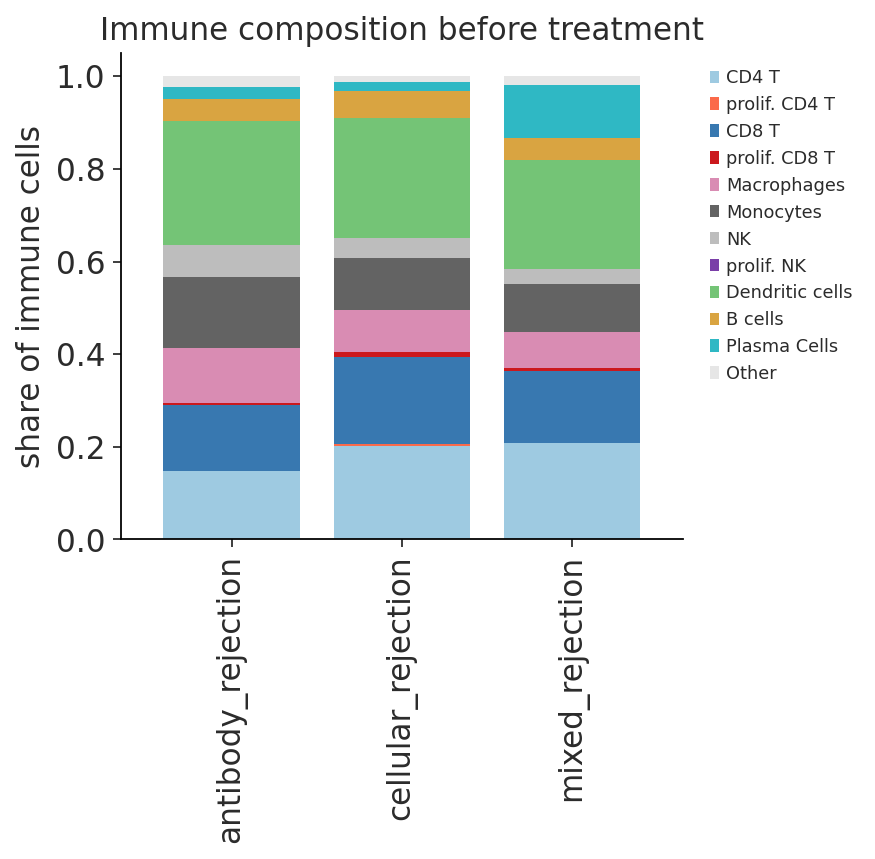

In [37]:
pre_treatment = overview["pre"]
composition = pre_treatment.filter(like="comp::")
composition.columns = composition.columns.str.removeprefix("comp::")
mean_composition = composition.groupby(pre_treatment["prt"]).mean()
ax = mean_composition.plot.bar(stacked=True, color=style.COMPOSITION, width=0.8, figsize=(4.5, 4))
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
ax.set(xlabel="", ylabel="share of immune cells", title="Immune composition before treatment")
plt.show()

`hhca.pl.core_overview` draws Fig 6 d from the pre-treatment table: one column per core with its clinical
tracks, immune fraction, foci and composition.

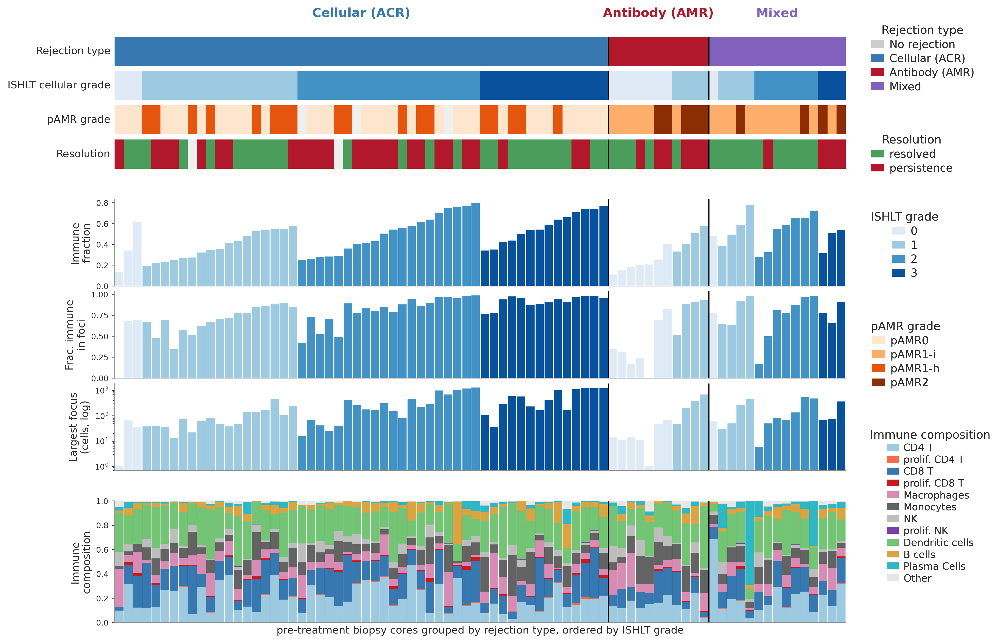

In [38]:
fig = hhca.pl.core_overview(overview["pre"], "pre")

The same drawing for the cores taken after treatment is ED9 a.

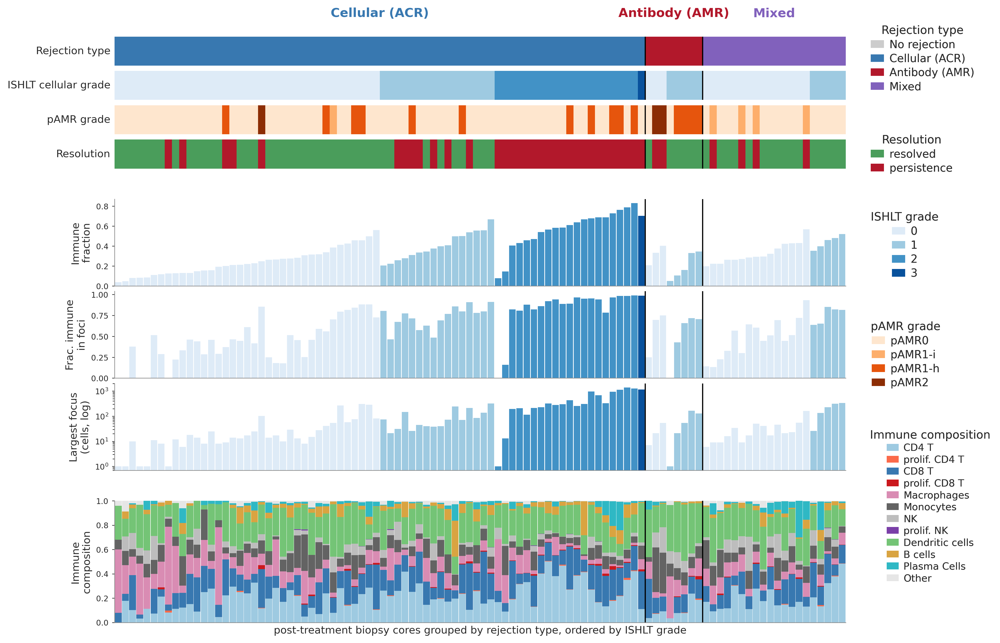

In [39]:
fig = hhca.pl.core_overview(overview["post"], "post")

Does the share of immune cells in foci follow the grade? `hhca.tl.core_grades` puts the cellular grade of each
core next to its foci, and we correlate the two with Spearman's ρ.

In [40]:
core_grades = hhca.tl.core_grades(adata, foci)
rho, p_value = stats.spearmanr(core_grades["grade"], core_grades["ff"])
print(f"{len(core_grades)} cores, Spearman rho = {rho:.2f}, p = {p_value:.1e}")
median_in_foci = core_grades.groupby("grade")["ff"].median()
median_in_foci.to_frame("median share of immune cells in foci")

188 cores, Spearman rho = 0.67, p = 2.1e-25


,median share of immune cells in foci
grade,
0.0,0.446429
1.0,0.716172
2.0,0.879271
3.0,0.925388


`hhca.pl.foci_by_grade` draws Fig 6 e.

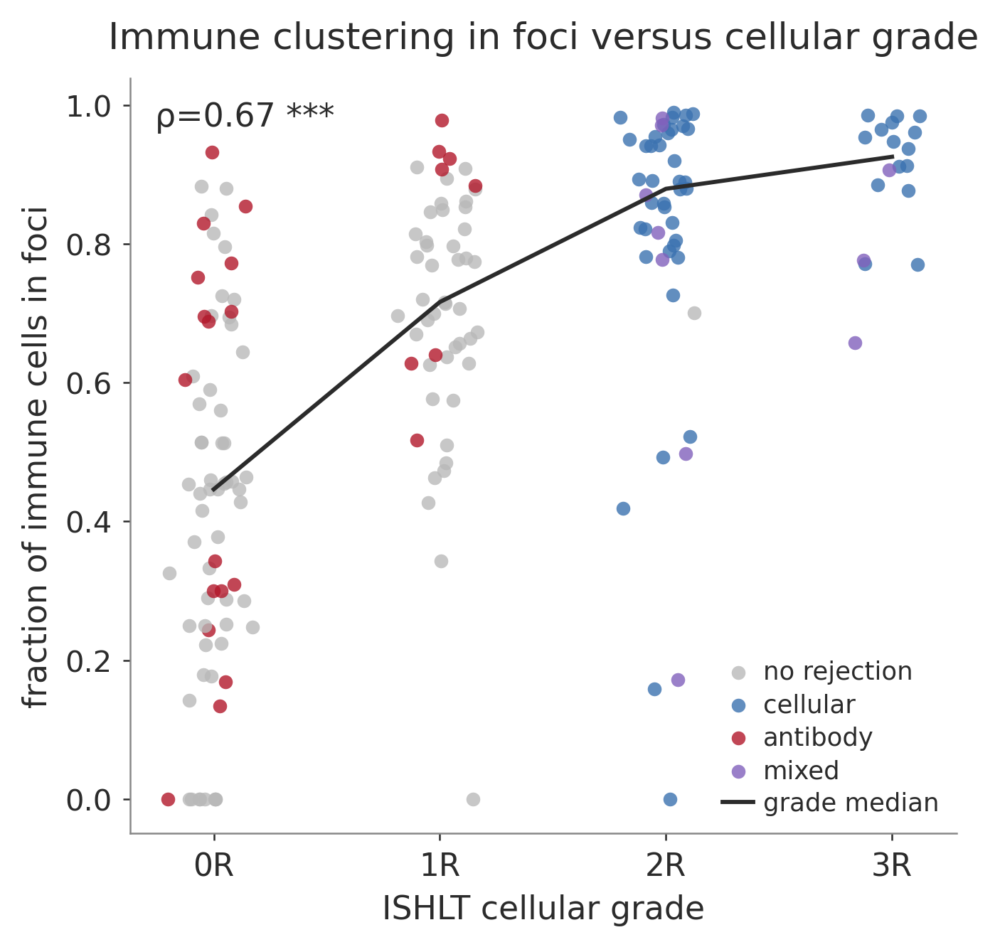

In [41]:
fig = hhca.pl.foci_by_grade(core_grades, rho, p_value)

In the example core 1,349 of the 1,370 immune cells lie in a focus. The median core has an immune fraction of
0.39 and 71% of its immune cells in foci; 80 cores enter the pre-treatment and 102 the post-treatment overview.
The share of immune cells in foci rises with the cellular grade, from a median of 0.45 at grade 0R to 0.93 at
grade 3R (188 cores, Spearman ρ = 0.67, p = 2.1e-25).

## Cytokine-response programmes

Which signals do the immune cells of a rejecting graft respond to? The panel holds few cytokine genes, but it
does hold genes that immune cells switch on in response to cytokines. The huCIRA dictionary lists these response
genes per cytokine and immune cell type; `hhca.tl.programme_genes` takes, for each of 18 cytokines, the union
over the cell types and keeps the genes of the panel.

In [42]:
with open(cfg["inputs"]["cytokine_programs"]) as handle:
    hucira = json.load(handle)["programs"]
cytokine_cfg = params["cytokine"]
programmes = hhca.tl.programme_genes(hucira, adata.var_names, cytokine_cfg["programmes"])
programmes[["cytokine", "n_union", "n_on_panel"]].set_index("cytokine").T

cytokine,IL-15,IL-2,IFN-beta,IL-1-beta,IFN-gamma,IL-4,IL-10,IL-12,IL-21,GM-CSF,IL-1-alpha,IFN-alpha1,IL-13,M-CSF,IL-6,OSM,TNF-alpha,IL-18
n_union,205,217,174,210,184,224,274,205,228,211,198,153,190,192,169,66,114,88
n_on_panel,26,23,15,29,15,10,4,12,17,15,14,9,6,11,14,7,6,7


`hhca.tl.score_programmes` scores every cell for every programme with `sc.tl.score_genes`: the mean expression
of the programme minus that of 50 control genes with similar expression. The score of a core is the mean over
its immune cells.

In [43]:
programme_sets = hhca.tl.gene_sets(programmes)
score_keys = hhca.tl.score_programmes(
    adata,
    programme_sets,
    prefix="c_",
    ctrl_size=cytokine_cfg["ctrl_size"],
    random_state=cytokine_cfg["random_state"],
)
immune_scores = adata.obs.loc[adata.obs["atlas_immune"], score_keys]
core_scores = immune_scores.groupby(sample).mean()
core_scores.columns = "score_" + programmes["cytokine"].to_numpy()
core_scores.iloc[:5, :6]

,score_IL-15,score_IL-2,score_IFN-beta,score_IL-1-beta,score_IFN-gamma,score_IL-4
Sample,,,,,,
Patient_10_1,0.219769,0.053266,0.236406,0.455572,0.236747,0.128670
Patient_10_2,0.085119,-0.063526,0.188176,0.319747,0.210449,0.017641
Patient_10_3,0.346193,0.200956,0.320079,0.494260,0.426095,0.074444
Patient_11_1,0.428405,0.308236,0.434100,0.539926,0.384109,0.216923
Patient_11_2,0.571038,0.428643,0.566639,0.699674,0.569729,0.210112


The same programmes can be resolved by cell type. `hhca.tl.programme_means` takes the mean expression of the
programme genes per cell (without control genes) and averages it per core and immune class, for groups of at
least ten cells and programmes with at least five genes on the panel.

In [44]:
celltype_cfg = params["celltype_cytokine"]
enough_panel_genes = programmes["n_on_panel"] >= celltype_cfg["min_panel_genes"]
celltype_sets = hhca.tl.gene_sets(programmes[enough_panel_genes])
celltype_scores = hhca.tl.programme_means(adata, celltype_sets, ("Sample", "ct"), min_cells=celltype_cfg["min_cells"])
n_cell_types = celltype_scores["ct"].nunique()
n_cores = celltype_scores["Sample"].nunique()
print(
    f"{len(celltype_scores):,} groups of {n_cell_types} cell types on {n_cores} cores, {len(celltype_sets)} programmes"
)

1,096 groups of 11 cell types on 182 cores, 17 programmes


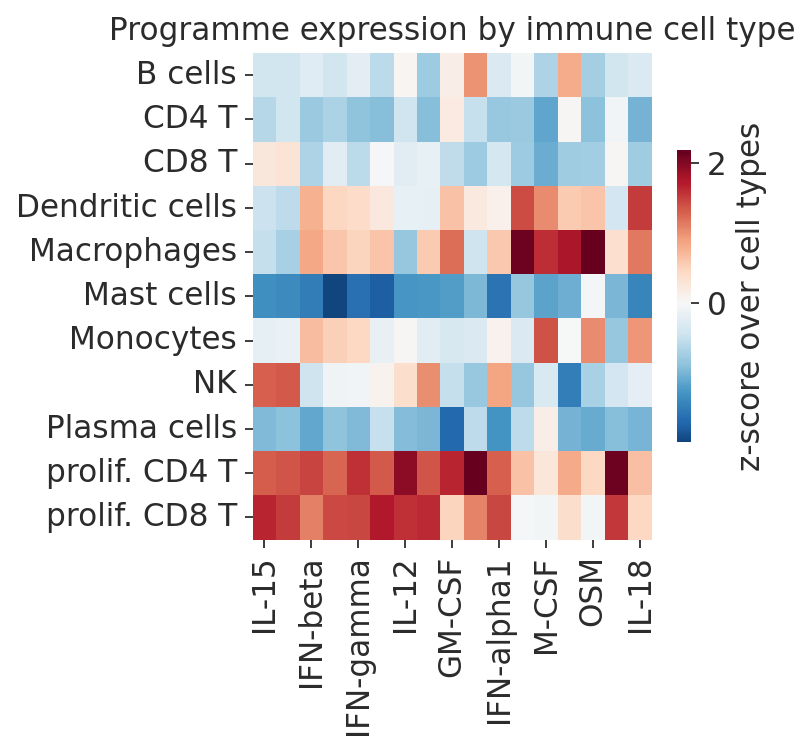

In [45]:
by_type = celltype_scores.groupby("ct")[list(celltype_sets)].mean()
by_type_z = (by_type - by_type.mean()) / by_type.std()
ax = sns.heatmap(
    by_type_z,
    cmap=style.DIVERGING,
    center=0,
    cbar_kws={"label": "z-score over cell types", "shrink": 0.6},
)
ax.set(xlabel="", ylabel="", title="Programme expression by immune cell type")
plt.show()

Between 4 (IL-10) and 29 (IL-1β) genes of a programme are on the panel. 17 programmes have at least five and are
resolved by cell type, in 1,096 groups of 11 cell types on 182 cores: proliferating T cells express most
programmes highly, macrophages the M-CSF and OSM programmes, and mast and plasma cells hardly any.

## Drug targets by cell type

Immunosuppressive drugs act on defined targets, and the labels tell us which cells of the graft carry them. The
drugs and their target genes are set in the configuration:

In [46]:
drugs = params["drugs"]
pd.Series(drugs).str.join(", ").to_frame("target genes")

,target genes
ATG (anti-thymocyte),"CD2, CD3D, CD3E, CD247, CD5, CD4, CD8A, CD27, ..."
Basiliximab (anti-CD25),IL2RA
Belatacept (CD80/86),"CD80, CD86"
Iscalimab (anti-CD40),CD40
Rituximab (anti-CD20),MS4A1
Bortezomib (proteasome),PSMB8
Tacrolimus (FKBP1A),FKBP1A
Sirolimus (mTOR),"MTOR, FKBP1A"


We score the target set of each drug per cell, as for the cytokine programmes, and group the cells into the
columns of the panel: lymphoid cells at Level 4, the other immune types, and endothelial, mural, fibroblast and
cardiomyocyte classes. `hhca.tl.group_zscores` returns the mean score per class and its z-score over the classes.

In [47]:
hhca.tl.cell_classes(
    adata, classes["drug_targets"], labels["lymphoid"], exclude=labels["exclude_l3"], key_added="ct_group"
)
drug_prefix = "d_"
hhca.tl.score_programmes(
    adata,
    drugs,
    prefix=drug_prefix,
    ctrl_size=cytokine_cfg["ctrl_size"],
    random_state=cytokine_cfg["random_state"],
)
drug_columns = {drug: f"{drug_prefix}{drug}" for drug in drugs}
drug_means, drug_z = hhca.tl.group_zscores(adata, drug_columns, "ct_group", classes["drug_target_order"])
drug_z.idxmax(axis=1).to_frame("class with the highest score")

,class with the highest score
ATG (anti-thymocyte),prolif. CD4 T
Basiliximab (anti-CD25),Macrophages
Belatacept (CD80/86),Dendritic cells
Iscalimab (anti-CD40),B cells
Rituximab (anti-CD20),B cells
Bortezomib (proteasome),prolif. CD4 T
Tacrolimus (FKBP1A),Endothelial
Sirolimus (mTOR),Endothelial


`hhca.pl.drug_targets` draws Fig 6 k.

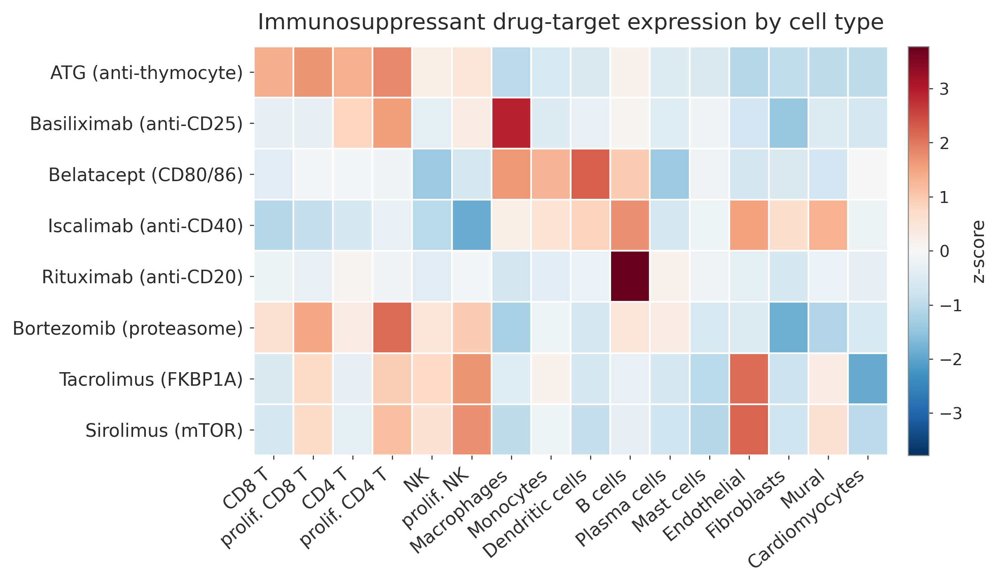

In [48]:
fig = hhca.pl.drug_targets(drug_z)

For the comparison with the infiltrate below we also need the score of the anti-thymocyte globulin (ATG) targets
per core, the mean over all its cells.

In [49]:
atg_per_core = adata.obs[drug_columns[params["atg_drug"]]].groupby(sample).mean()
atg = atg_per_core.to_frame("drug_target_score")
atg.describe().loc[["count", "min", "50%", "max"]]

,drug_target_score
count,195.000000
min,-0.484585
50%,-0.076367
max,1.248317


The ATG targets score highest in proliferating CD4 T cells, the targets of rituximab and iscalimab in B cells,
those of belatacept in dendritic cells and IL2RA, the target of basiliximab, in macrophages. FKBP1A and MTOR,
the targets of tacrolimus and sirolimus, are highest in endothelial cells. Per core, the ATG score ranges from
−0.48 to 1.25.

## From cores to biopsies

Rejection type, grade and outcome are properties of a biopsy, and the two cores of a biopsy are not independent.
`hhca.tl.biopsy_cohort` therefore joins the per-core tables and averages the cores of each biopsy. The rejection
type of a biopsy combines its cores: cellular and antibody-mediated rejection in the same biopsy make it mixed.
Biopsies without rejection in their cores that were taken before the treatment of a rejection episode
(`core_neg`) are left out of the comparisons by rejection type.

In [50]:
cores, biopsies, programme_columns = hhca.tl.biopsy_cohort(
    metadata, core_scores, foci, atg, grade_rule=labels["grade_rule"], rejection_rule=labels["rejection_rule"]
)
labelled = biopsies[~biopsies["core_neg"]]
scored = labelled.dropna(subset=["rej", *programme_columns])
n_patients = biopsies["patient"].nunique()
n_core_negative = biopsies["core_neg"].sum()
print(f"{len(biopsies)} biopsies of {n_patients} patients, {n_core_negative} core-negative")
scored["rej"].value_counts().to_frame("biopsies with a rejection type and scores")

108 biopsies of 62 patients, 8 core-negative


,biopsies with a rejection type and scores
rej,
cellular_rejection,39
no_rejection,37
antibody_rejection,12
mixed_rejection,7


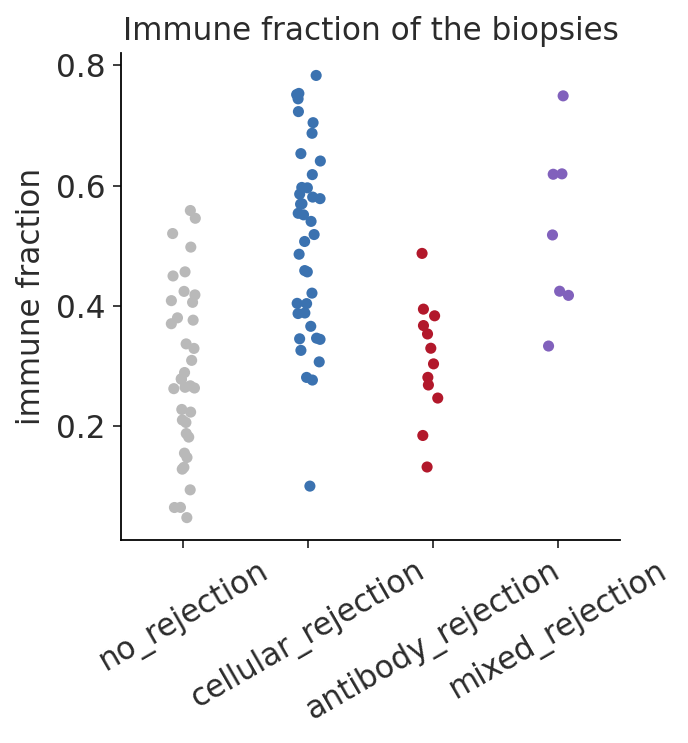

In [51]:
ax = sns.stripplot(
    scored,
    x="rej",
    y="immf",
    order=list(style.REJECTION),
    hue="rej",
    palette=style.REJECTION,
    legend=False,
)
ax.set(xlabel="", ylabel="immune fraction", title="Immune fraction of the biopsies")
ax.tick_params(axis="x", rotation=30)
plt.show()

At the level of biopsies the grade still follows the foci. Because a patient can contribute several biopsies,
`hhca.tl.foci_by_grade` adds a permutation p value for which the grades are shuffled between patients.

In [52]:
grade_test = hhca.tl.foci_by_grade(labelled, params["permutations"])
pd.Series(grade_test, dtype=object).to_frame("grade against foci, biopsies")

,"grade against foci, biopsies"
n,100
patients,62
rho,0.567877
p,0.0
p_perm,0.0002


The 108 biopsies of 62 patients include 8 core-negative ones; 95 have a rejection type and programme scores (39
cellular, 37 without rejection, 12 antibody-mediated, 7 mixed). Over 100 biopsies the grade correlates with the
share of immune cells in foci (ρ = 0.57, p = 7.2e-10; permutation p = 0.0002).

## Cytokine programmes by rejection type

Now we can ask whether the rejection types differ in their cytokine programmes. `hhca.tl.programmes_vs_no_rejection`
compares each rejecting type with the biopsies without rejection (Mann–Whitney U, Benjamini–Hochberg over all
54 tests) and returns the programme medians as z-scores over the four types.

In [53]:
alpha = cfg["notebook"]["alpha"]
programme_z, programme_tests = hhca.tl.programmes_vs_no_rejection(scored, programme_columns)
significant = programme_tests[programme_tests["q"] < alpha]
significant.sort_values("q")

,programme,group,p,q
9,score_IL-1-beta,cellular_rejection,0.000111,0.004551
6,score_IFN-beta,cellular_rejection,0.000169,0.004551
3,score_IL-2,cellular_rejection,0.002580,0.029836
0,score_IL-15,cellular_rejection,0.001759,0.029836
33,score_IFN-alpha1,cellular_rejection,0.002763,0.029836
21,score_IL-12,cellular_rejection,0.004553,0.034067
26,score_IL-21,mixed_rejection,0.005047,0.034067
41,score_M-CSF,mixed_rejection,0.004473,0.034067


`hhca.pl.programme_heatmap` draws Fig 6 h.

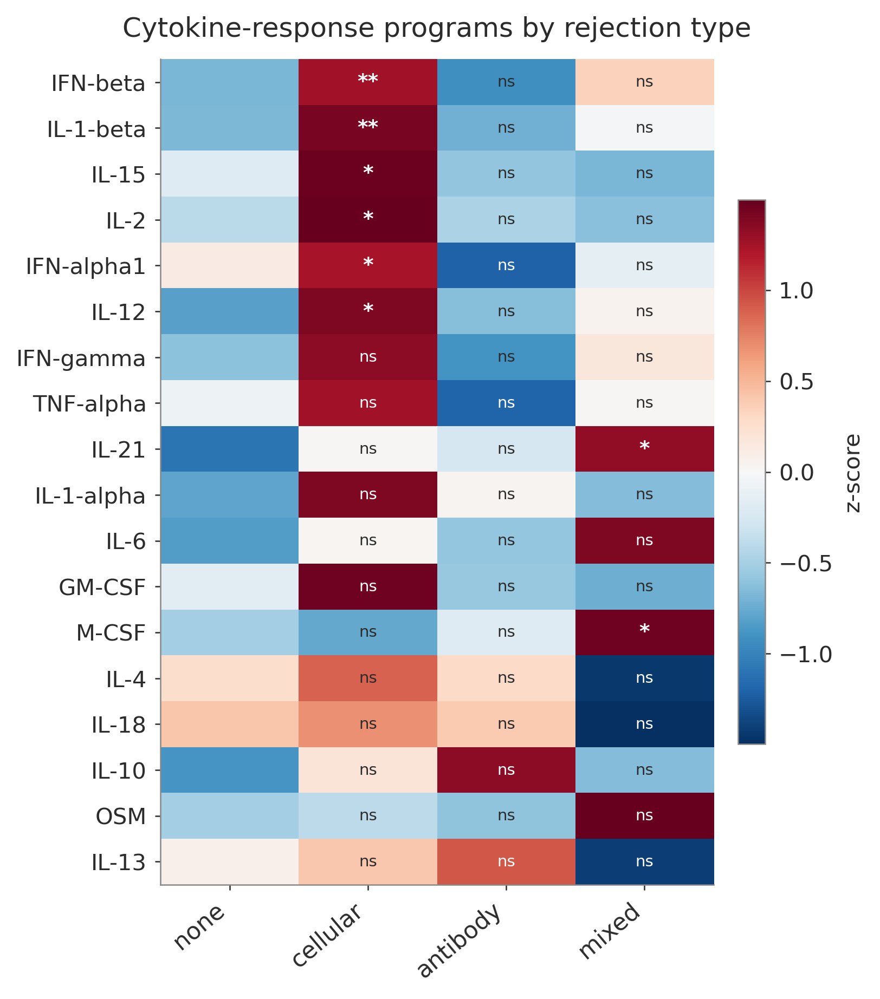

In [54]:
fig = hhca.pl.programme_heatmap(programme_z, programme_tests)

`hhca.tl.programmes_by_rejection` tests each programme across all four types (Kruskal–Wallis,
Benjamini–Hochberg over the 18 programmes) and every pair of types (Mann–Whitney U, Benjamini–Hochberg over the
six pairs).

In [55]:
rejection_tests = hhca.tl.programmes_by_rejection(scored, programme_columns)
rejection_tests = rejection_tests.set_index("column")
shown = ["cytokine", "kruskal_p", "kruskal_q_BH_over_18", "median_none", "median_cellular", "q_none_vs_cellular"]
rejection_tests.sort_values("kruskal_p")[shown].head(6)

,cytokine,kruskal_p,kruskal_q_BH_over_18,median_none,median_cellular,q_none_vs_cellular
column,,,,,,
score_IL-1-beta,IL-1β,0.000408,0.007344,0.268537,0.370278,0.000664
score_IFN-beta,IFN-β,0.001098,0.009885,0.077283,0.202790,0.001011
score_IFN-alpha1,IFN-α1,0.003679,0.022077,-0.004747,0.082939,0.016576
score_IL-15,IL-15,0.006673,0.030027,0.094043,0.187338,0.010557
score_IL-2,IL-2,0.009388,0.033796,-0.015068,0.064690,0.015481
score_IL-21,IL-21,0.024750,0.072987,0.004045,0.029728,0.085136


For the IL-1β programme we also ask whether the difference survives when the rejection types are shuffled
between patients (`hhca.tl.kruskal_permutation`).

In [56]:
figures = cfg["figures"]
programme_column = f"score_{figures['fig6i_programme']}"
programme_test = hhca.tl.kruskal_permutation(scored, programme_column, params["permutations"])
print(
    f"biopsies per type {programme_test['n']}, Kruskal-Wallis p = {programme_test['kruskal_p']:.1e}, "
    f"permutation p = {programme_test['p_perm']:.4f}"
)

biopsies per type [37, 39, 12, 7], Kruskal-Wallis p = 4.1e-04, permutation p = 0.0006


`hhca.pl.programme_scores` draws the scores of one programme by rejection type (Fig 6 i) ...

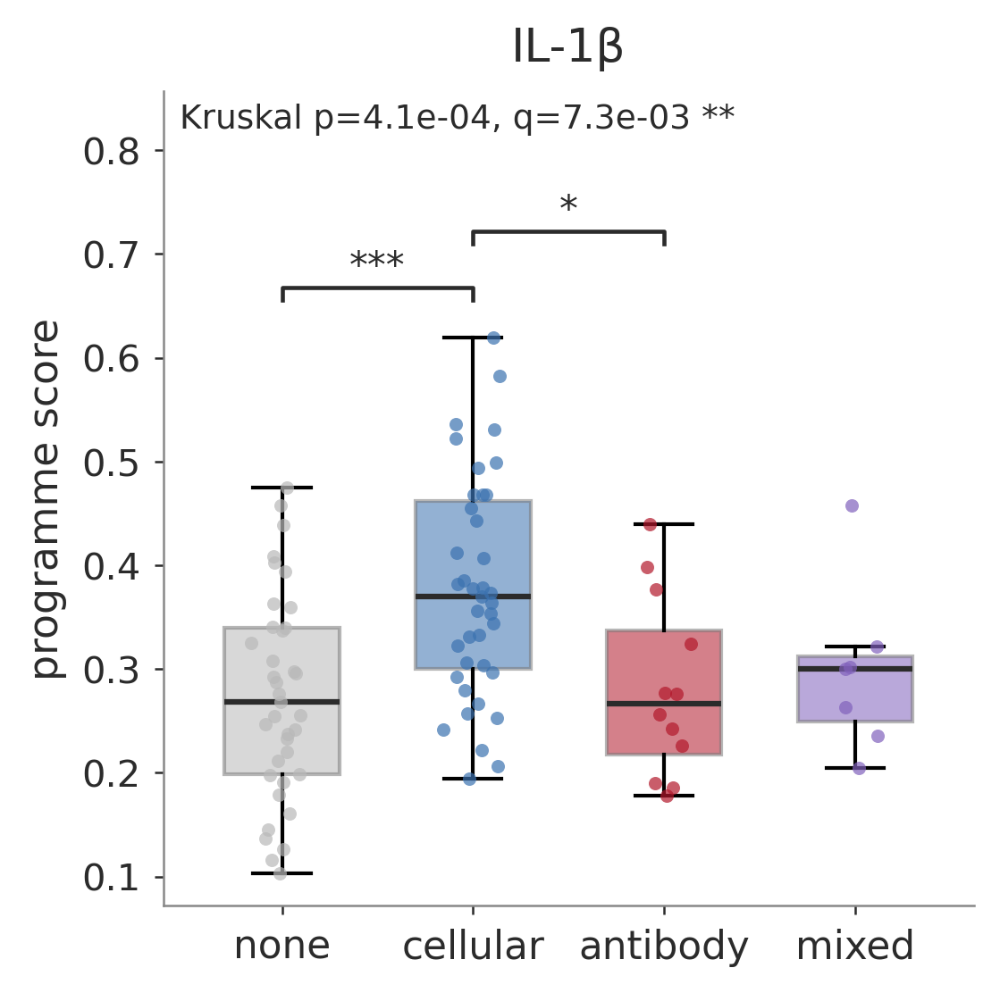

In [57]:
fig = hhca.pl.programme_scores(scored, rejection_tests, figures["fig6i_programme"])

... and of the other programmes on a grid (ED9 b and c).

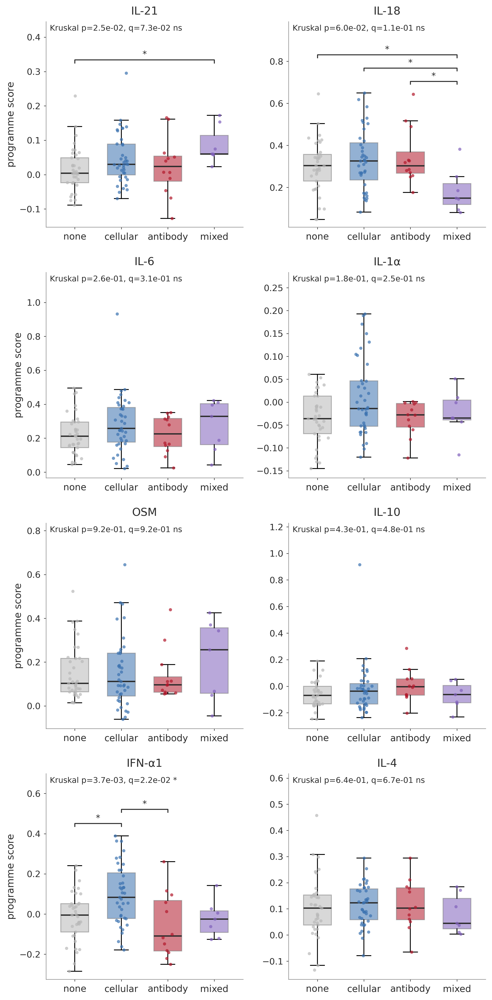

In [58]:
fig = hhca.pl.programme_scores(scored, rejection_tests, figures["ed9b_programmes"], (4, 2))

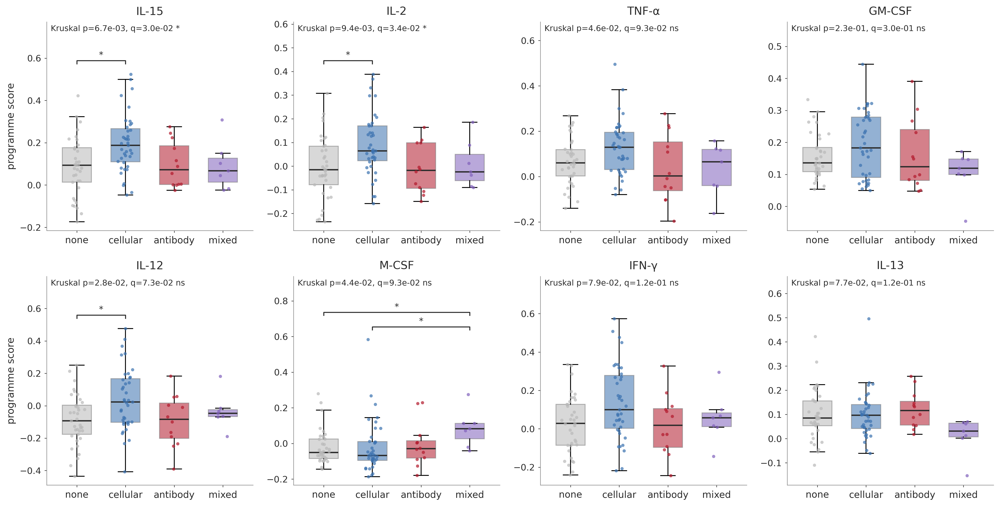

In [59]:
fig = hhca.pl.programme_scores(scored, rejection_tests, figures["ed9c_programmes"], (2, 4))

8 of the 54 comparisons with no rejection are significant: the IL-1β, IFN-β, IL-2, IL-15, IFN-α1 and IL-12
programmes are higher in cellular rejection and the IL-21 and M-CSF programmes in mixed rejection, while
antibody-mediated rejection differs in none. Across the four types five programmes differ at q < 0.05, led by
IL-1β (Kruskal–Wallis p = 4.1e-04, q = 0.0073; permutation p = 0.0006).

## Before and after treatment

Most patients with a rejection episode have a biopsy before and one after treatment, and the cohort records
whether the rejection resolved. `hhca.tl.pre_post_pairs` pairs the two biopsies of each patient and tests the
immune fraction (`f`) and the T-cell fraction (`g`) before against after treatment within each outcome
(Wilcoxon signed-rank test).

In [60]:
pairs, pair_tests = hhca.tl.pre_post_pairs(biopsies)
pd.DataFrame(pair_tests).T

,n,median_pre,median_post,p
f_resolved,26.0,0.549607,0.308999,0.000009
f_persistence,20.0,0.419133,0.398954,0.409098
g_resolved,26.0,0.209385,0.090105,0.000082
g_persistence,20.0,0.156734,0.205131,0.927279


`hhca.pl.pre_post` draws the immune fraction (Fig 6 f) and the T-cell fraction (Fig 6 g).

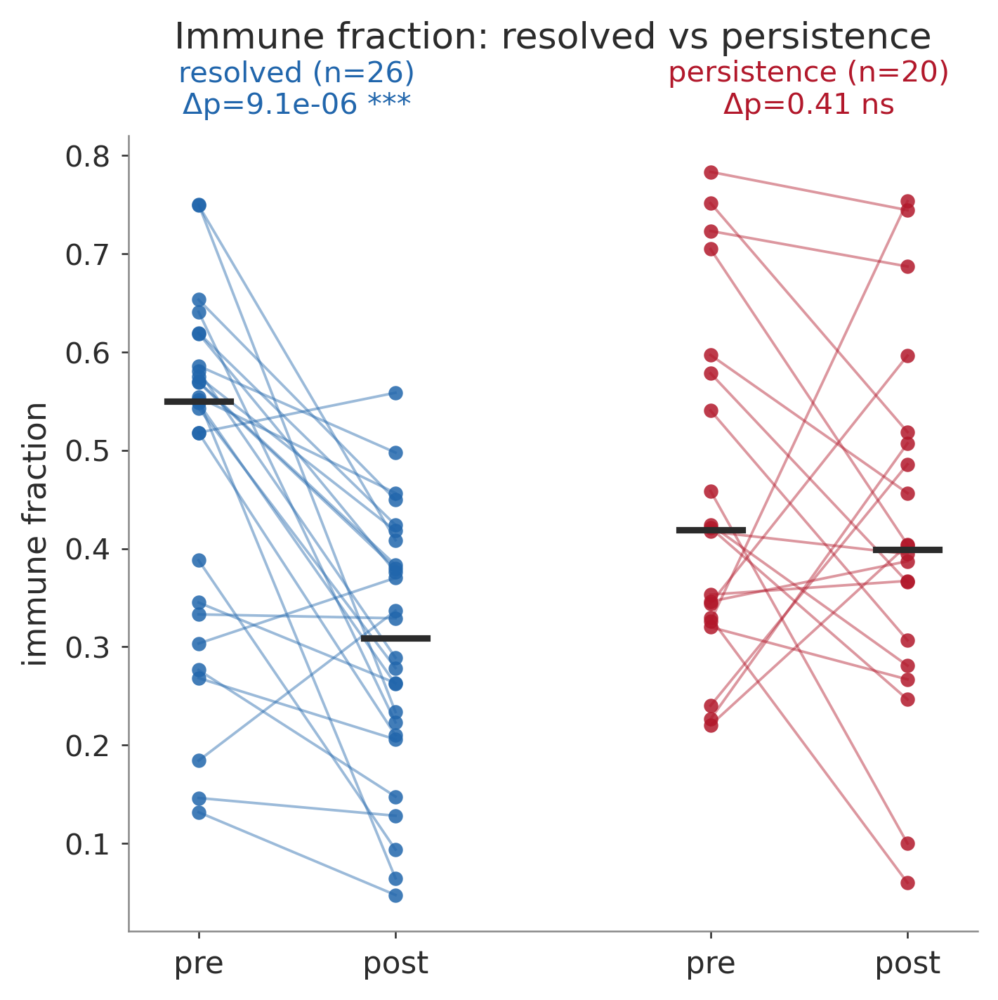

In [61]:
outcomes = list(style.RESOLUTION)
immune_fraction_tests = {outcome: pair_tests[f"f_{outcome}"] for outcome in outcomes}
fig = hhca.pl.pre_post(pairs, immune_fraction_tests, "immf", "immune fraction")

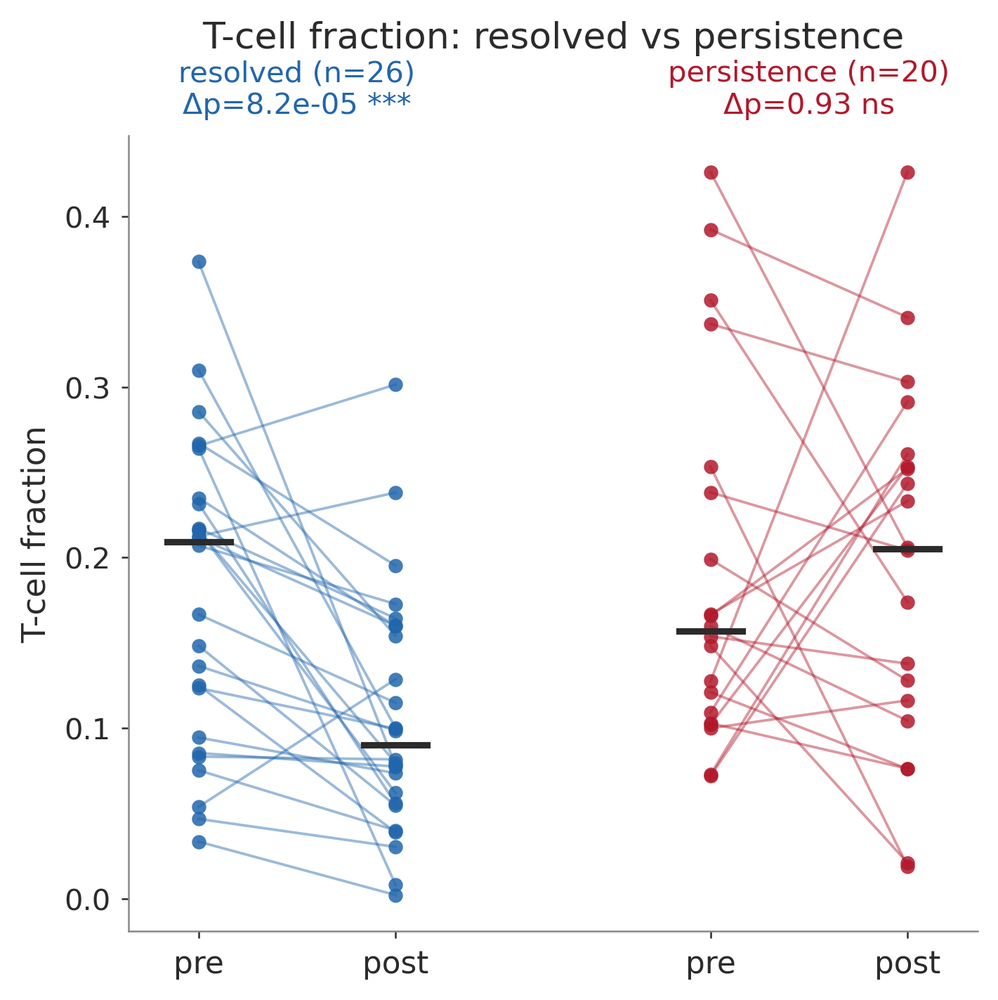

In [62]:
t_cell_fraction_tests = {outcome: pair_tests[f"g_{outcome}"] for outcome in outcomes}
fig = hhca.pl.pre_post(pairs, t_cell_fraction_tests, "tf", "T-cell fraction")

Can the biopsy taken *before* treatment tell which rejection will persist? One candidate is the IL-4 programme
in CD4 T cells. `hhca.tl.pool_cell_types` joins resting and proliferating CD4 T cells of a core, weighted by
their cell numbers, and `hhca.tl.outcome_test` compares persistent with resolved rejection (Mann–Whitney U; the
AUC is U divided by the product of the group sizes).

In [63]:
pooled_name = "CD4 T (pooled)"
pooled_cd4 = hhca.tl.pool_cell_types(celltype_scores, classes["cd4_pool"], pooled_name)
_, il4_test = hhca.tl.outcome_test(biopsies, cores, pooled_cd4, "IL-4")
pd.Series(il4_test, dtype=object).to_frame("IL-4 programme in CD4 T cells, persistence against resolved")

,"IL-4 programme in CD4 T cells, persistence against resolved"
n,46
resolved,25
persistence,21
p,0.098137
auc,0.64381


This is one test out of many that could have been run. `hhca.tl.outcome_tests` runs all of them, every immune
class and every programme, and corrects over the whole family.

In [64]:
biopsy_of_core = metadata.set_index("Sample")["bxid"]
celltype_scores["bxid"] = celltype_scores["Sample"].map(biopsy_of_core)
pooled_cd4["bxid"] = pooled_cd4["Sample"].map(biopsy_of_core)
family = pd.concat([celltype_scores.drop(columns="n_cells"), pooled_cd4], ignore_index=True)
outcome_biopsies = hhca.tl.outcome_cohort(metadata)
outcome_tests = hhca.tl.outcome_tests(family, outcome_biopsies, params["outcome_min_biopsies"], pooled=pooled_name)
n_tests = len(outcome_tests)
n_nominal = (outcome_tests["p"] < alpha).sum()
smallest_q = outcome_tests["q_BH_all"].min()
print(f"{n_tests} tests, {n_nominal} with p < {alpha}, smallest q = {smallest_q:.2f}")
outcome_tests[["ct", "programme", "n_resolved", "n_persistence", "p", "auc", "q_BH_all"]].head()

170 tests, 8 with p < 0.05, smallest q = 0.67


,ct,programme,n_resolved,n_persistence,p,auc,q_BH_all
0,Macrophages,IL-13,21,20,0.015840,0.721429,0.673602
1,NK,IL-6,14,15,0.017380,0.761905,0.673602
2,CD4 T (pooled),IL-1-beta,25,21,0.029020,0.689524,0.673602
3,CD8 T,GM-CSF,24,21,0.029803,0.690476,0.673602
4,CD4 T (pooled),OSM,25,21,0.030683,0.687619,0.673602


In the 26 patients whose rejection resolved, the immune fraction falls from a median of 0.55 to 0.31 and the
T-cell fraction from 0.21 to 0.09 (p = 9.2e-06 and 8.2e-05); in the 20 patients with persistent rejection neither
changes (p = 0.41 and 0.93). The IL-4 programme of CD4 T cells is somewhat higher before treatment in the 21
biopsies of persistent than in the 25 of resolved rejection (AUC 0.64, p = 0.098), but it is one of 170 tests of
which 8 have p < 0.05, about what chance gives, and none survives correction (smallest q = 0.67).

## ATG targets and the infiltrate

Finally we return to the drug targets. If the ATG score of a core mostly counts T cells, it should follow the
immune and the T-cell fraction of the biopsies.

In [65]:
correlations = hhca.tl.score_correlations(biopsies, "atg", ("immf", "tf"))
pd.DataFrame(correlations).T

,n,rho,p
immf,108.0,0.819019,2.505548e-27
tf,108.0,0.970848,1.396113e-67


`hhca.pl.atg_score` draws both comparisons (Fig 6 l).

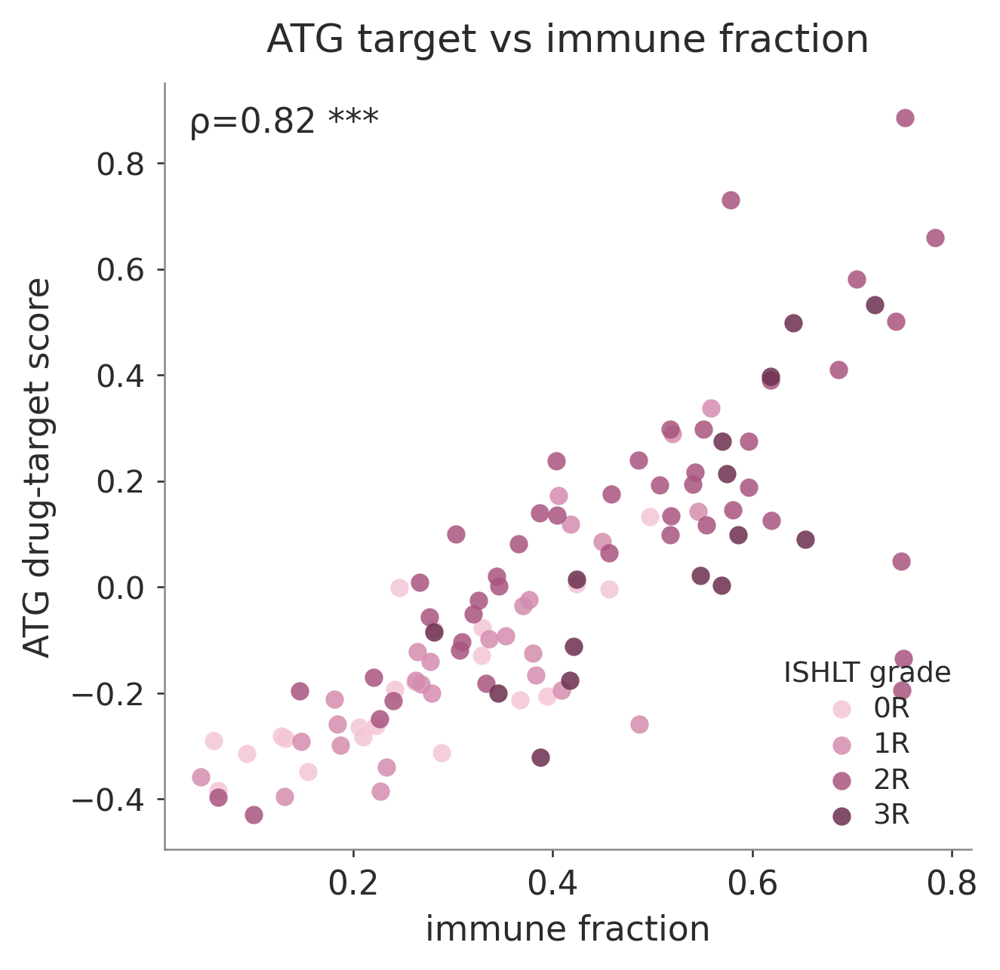

In [66]:
fig = hhca.pl.atg_score(biopsies, "immf", "immune fraction", correlations["immf"]["rho"], correlations["immf"]["p"])

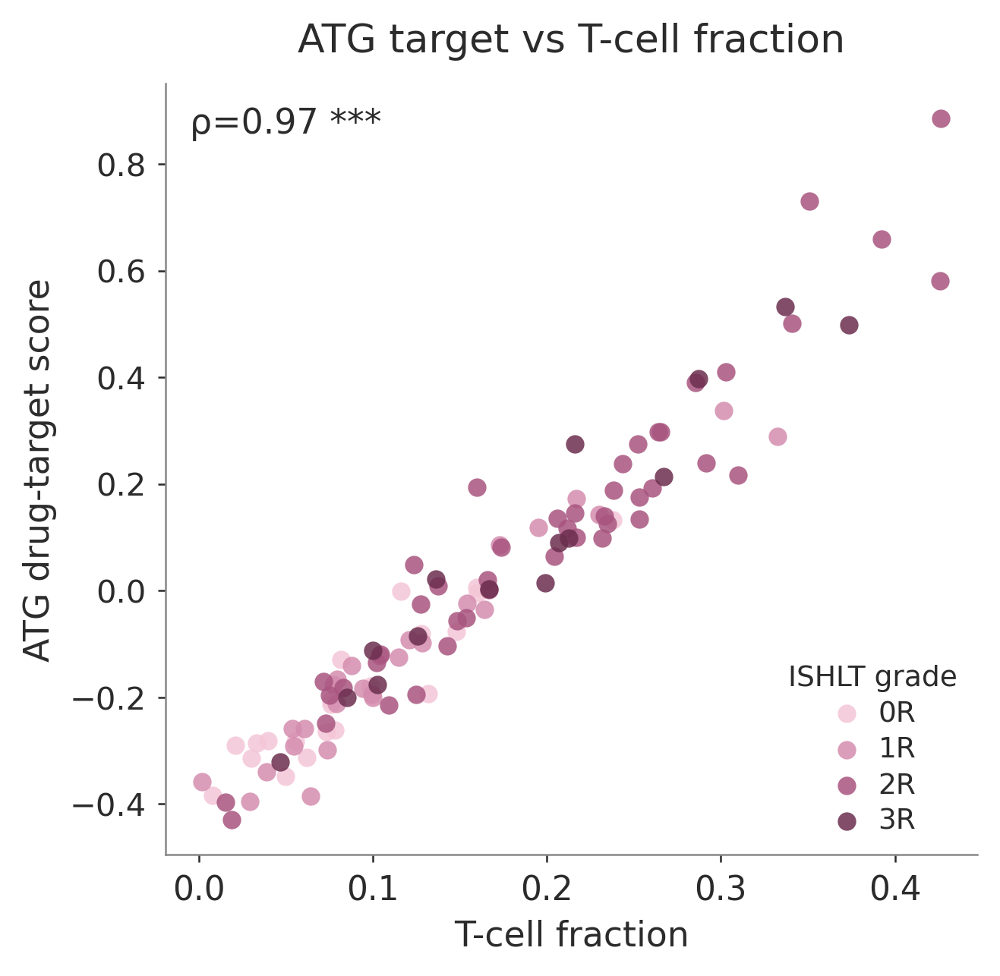

In [67]:
fig = hhca.pl.atg_score(biopsies, "tf", "T-cell fraction", correlations["tf"]["rho"], correlations["tf"]["p"])

Over the 108 biopsies the ATG score follows the immune fraction (ρ = 0.82) and, more closely, the T-cell fraction
(ρ = 0.97), as expected of a set of T-cell genes.

## Key takeaways

- CellPin transfers the Level-3 labels of the heart atlas to Xenium cells; marker genes of the panels support
  them, and an endothelial marker gate removes 799 of 2,770 endothelial labels on the healthy section.
- The 33,965 lymphoid cells of the rejection cohort are split into CD4 T, CD8 T and NK cells, resting or
  proliferating; regulatory T cells and ILC cannot be labelled reliably and are left out.
- Immune cells gather in foci, and the share of immune cells in foci follows the ISHLT cellular grade
  (ρ = 0.67 over 188 cores).
- Cellular rejection carries higher IL-1β, interferon, IL-2, IL-12 and IL-15 response programmes; antibody-mediated
  rejection does not differ from no rejection.
- Immune and T-cell fractions fall after treatment where rejection resolves and stay where it persists; no
  programme of the pre-treatment biopsy predicts the outcome after correction for multiple testing.
- Every step is one function of `hhca.tl` and every panel one function of `hhca.pl`, so the same code runs here
  and in the pipeline scripts.